# Judul PI :
```
Kerangka Prediksi Hoaks Multi-Layer untuk Konten Digital Indonesia: Integrasi Fitur Berbasis Transformer dan Verifikasi Sumber Eksternal
```
### Scraping Dataset
### Scrape Kompas

In [ ]:
import requests
import re
import pandas as pd
from typing import List, Dict

BASE_URL = "https://www.kompas.com/cekfakta/data-dan-fakta/{}"
HEADERS = {
    "User-Agent": "Mozilla/5.0"
}


def fetch_html(url: str) -> str:
    """Fetch HTML content from a URL."""
    try:
        response = requests.get(url, headers=HEADERS, timeout=10)
        response.raise_for_status()
        return response.text
    except requests.RequestException:
        return ""


def extract_article_links(html: str) -> List[str]:
    """Extract valid article links from page HTML."""
    links = re.findall(r'href="(.*?)"', html)
    return [link for link in links if "cekfakta/read" in link]


def scrape_links(pages: int = 120) -> List[str]:
    """Scrape all article links from multiple pages."""
    all_links = set()

    for page in range(1, pages + 1):
        url = BASE_URL.format(page)
        html = fetch_html(url)
        if not html:
            continue

        links = extract_article_links(html)
        all_links.update(links)

    return list(all_links)


def parse_article(html: str) -> Dict[str, str]:
    """Extract title and content from article HTML."""
    # Title
    title_match = re.search(r'<h1 class="read__title">(.*?)</h1>', html)
    title = title_match.group(1).strip() if title_match else None

    # Content
    content_match = re.search(
        r'<div\s+[^>]*class=["\']read__content["\'][^>]*>(.*?)</div>',
        html,
        re.DOTALL
    )

    if not content_match:
        return {}

    raw_html = content_match.group(1)

    paragraphs = re.findall(r'<p[^>]*>(.*?)</p>', raw_html, re.DOTALL)
    clean_text = " ".join(paragraphs)
    clean_text = re.sub(r'<[^>]+>', '', clean_text).strip()

    if not title or not clean_text:
        return {}

    return {
        "TITLE": title,
        "NARRATIVE": clean_text,
        "LABEL": 1
    }


def scrape_articles(links: List[str]) -> List[Dict]:
    """Scrape all articles from given links."""
    data = []

    for link in links:
        html = fetch_html(link)
        if not html:
            continue

        article = parse_article(html)
        if article:
            data.append(article)

    return data


def save_to_csv(data: List[Dict], filename: str = "kompas_dataset.csv"):
    """Save scraped data to CSV."""
    df = pd.DataFrame(data)
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Dataset saved to {filename}")


if __name__ == "__main__":
    links = scrape_links(pages=120)
    print(f"Collected {len(links)} unique links.")

    articles = scrape_articles(links)
    print(f"Collected {len(articles)} articles.")

    save_to_csv(articles)

Collected 1085 unique links.
Collected 1085 articles.
Dataset saved to kompas_dataset.csv


## Scrape Komdigi

### Fact News

In [ ]:
import requests
import json
import re
import pandas as pd
from typing import List, Dict

BASE_URL = "https://web.komdigi.go.id/api/v1/contents/category/berita-pemerintahan"
DETAIL_URL = "https://web.komdigi.go.id/api/v1/content/detail/berita-pemerintahan/{}"

HEADERS = {
    "User-Agent": "Mozilla/5.0",
    "Accept": "*/*",
    "Referer": "https://www.komdigi.go.id/",
    "Origin": "https://www.komdigi.go.id"
}


def fetch_json(url: str) -> Dict:
    """Fetch JSON data safely."""
    try:
        response = requests.get(url, headers=HEADERS, timeout=10)
        response.raise_for_status()
        return response.json()
    except requests.RequestException:
        return {}


def get_slugs(pages: int = 120) -> List[str]:
    """Collect slugs from multiple pages."""
    all_slugs = set()

    for page in range(1, pages + 1):
        url = f"{BASE_URL}?perPage=12&page={page}&keyword="
        data = fetch_json(url)

        items = data.get("response", {}).get("data", [])
        for item in items:
            slug = item.get("slug")
            if slug:
                all_slugs.add(slug)

        print(f"Page {page}: collected {len(items)} items")

    return list(all_slugs)


def clean_html(text: str) -> str:
    """Remove HTML tags."""
    return re.sub(r"<[^>]+>", "", text).strip()


def fetch_article(slug: str) -> Dict:
    """Fetch single article detail."""
    url = DETAIL_URL.format(slug)
    data = fetch_json(url)

    article = data.get("data", {})
    title = article.get("title")
    body_html = article.get("body", "")

    clean_text = clean_html(body_html)

    if title and clean_text:
        return {
            "TITLE": title,
            "NARRATIVE": clean_text,
            "LABEL": 1
        }

    return {}


def scrape_articles(slugs: List[str]) -> List[Dict]:
    """Fetch all articles from slug list."""
    results = []

    for i, slug in enumerate(slugs, 1):
        article = fetch_article(slug)
        if article:
            results.append(article)

        if i % 10 == 0:
            print(f"Processed {i}/{len(slugs)} articles")

    return results


def save_to_csv(data: List[Dict], filename: str):
    """Save data to CSV."""
    df = pd.DataFrame(data)
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Saved {len(df)} articles to {filename}")


if __name__ == "__main__":
    print("Collecting slugs...")
    slugs = get_slugs(pages=120)
    print(f"Total unique slugs: {len(slugs)}")

    print("\nFetching article details...")
    articles = scrape_articles(slugs)

    save_to_csv(articles, "komdigi_fact_dataset.csv")

    # Preview
    df_preview = pd.DataFrame(articles)
    print("\nPreview:")
    print(df_preview.head())

Page 1: collected 12 items
Page 2: collected 12 items
Page 3: collected 12 items
Page 4: collected 12 items
Page 5: collected 12 items
Page 6: collected 12 items
Page 7: collected 12 items
Page 8: collected 12 items
Page 9: collected 12 items
Page 10: collected 12 items
Page 11: collected 12 items
Page 12: collected 12 items
Page 13: collected 12 items
Page 14: collected 12 items
Page 15: collected 12 items
Page 16: collected 12 items
Page 17: collected 12 items
Page 18: collected 12 items
Page 19: collected 12 items
Page 20: collected 12 items
Page 21: collected 12 items
Page 22: collected 12 items
Page 23: collected 12 items
Page 24: collected 12 items
Page 25: collected 12 items
Page 26: collected 12 items
Page 27: collected 12 items
Page 28: collected 12 items
Page 29: collected 12 items
Page 30: collected 12 items
Page 31: collected 12 items
Page 32: collected 12 items
Page 33: collected 12 items
Page 34: collected 12 items
Page 35: collected 12 items
Page 36: collected 12 items
P

### Fake News

In [ ]:
import requests
import json
import re
import pandas as pd
from typing import List, Dict

BASE_URL = "https://web.komdigi.go.id/api/v1/contents/category/berita-hoaks"
DETAIL_URL = "https://web.komdigi.go.id/api/v1/content/detail/berita-hoaks/{}"

HEADERS = {
    "User-Agent": "Mozilla/5.0",
    "Accept": "*/*",
    "Referer": "https://www.komdigi.go.id/",
    "Origin": "https://www.komdigi.go.id"
}


def fetch_json(url: str) -> Dict:
    """Fetch JSON data safely."""
    try:
        response = requests.get(url, headers=HEADERS, timeout=10)
        response.raise_for_status()
        return response.json()
    except requests.RequestException:
        return {}


def get_slugs(pages: int = 193) -> List[str]:
    """Collect slugs from multiple pages."""
    all_slugs = set()

    for page in range(1, pages + 1):
        url = f"{BASE_URL}?perPage=12&page={page}&keyword="
        data = fetch_json(url)

        items = data.get("response", {}).get("data", [])
        for item in items:
            slug = item.get("slug")
            if slug:
                all_slugs.add(slug)

        print(f"Page {page}: collected {len(items)} items")

    return list(all_slugs)


def clean_html(text: str) -> str:
    """Remove HTML tags."""
    return re.sub(r"<[^>]+>", "", text).strip()


def fetch_article(slug: str) -> Dict:
    """Fetch single article detail."""
    url = DETAIL_URL.format(slug)
    data = fetch_json(url)

    article = data.get("data", {})
    title = article.get("title")
    body_html = article.get("body", "")

    clean_text = clean_html(body_html)

    if title and clean_text:
        return {
            "TITLE": title,
            "NARRATIVE": clean_text,
            "LABEL": 0
        }

    return {}


def scrape_articles(slugs: List[str]) -> List[Dict]:
    """Fetch all articles from slug list."""
    results = []

    for i, slug in enumerate(slugs, 1):
        article = fetch_article(slug)
        if article:
            results.append(article)

        if i % 10 == 0:
            print(f"Processed {i}/{len(slugs)} articles")

    return results


def save_to_csv(data: List[Dict], filename: str):
    """Save data to CSV."""
    df = pd.DataFrame(data)
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Saved {len(df)} articles to {filename}")


if __name__ == "__main__":
    print("Collecting slugs...")
    slugs = get_slugs(pages=193)
    print(f"Total unique slugs: {len(slugs)}")

    print("\nFetching article details...")
    articles = scrape_articles(slugs)

    save_to_csv(articles, "komdigi_hoax_dataset.csv")

    # Preview
    df_preview = pd.DataFrame(articles)
    print("\nPreview:")
    print(df_preview.head())

Page 1: collected 12 items
Page 2: collected 12 items
Page 3: collected 12 items
Page 4: collected 12 items
Page 5: collected 12 items
Page 6: collected 12 items
Page 7: collected 12 items
Page 8: collected 12 items
Page 9: collected 12 items
Page 10: collected 12 items
Page 11: collected 12 items
Page 12: collected 12 items
Page 13: collected 12 items
Page 14: collected 12 items
Page 15: collected 12 items
Page 16: collected 12 items
Page 17: collected 12 items
Page 18: collected 12 items
Page 19: collected 12 items
Page 20: collected 12 items
Page 21: collected 12 items
Page 22: collected 12 items
Page 23: collected 12 items
Page 24: collected 12 items
Page 25: collected 12 items
Page 26: collected 12 items
Page 27: collected 12 items
Page 28: collected 12 items
Page 29: collected 12 items
Page 30: collected 12 items
Page 31: collected 12 items
Page 32: collected 12 items
Page 33: collected 12 items
Page 34: collected 12 items
Page 35: collected 12 items
Page 36: collected 12 items
P

## Scrape TurnBackHoax

In [ ]:
import requests
import re
import pandas as pd
import concurrent.futures
from typing import List, Dict

BASE_URL = "https://turnbackhoax.id/articles?category=all&page={}"

HEADERS = {
    "User-Agent": "Mozilla/5.0"
}


def fetch_html(url: str) -> str:
    """Fetch HTML safely."""
    try:
        response = requests.get(url, headers=HEADERS, timeout=10)
        response.raise_for_status()
        return response.text
    except requests.RequestException:
        return ""


def collect_links(max_pages: int = 120) -> List[str]:
    """Collect article links from multiple pages."""
    all_links = set()

    for page in range(1, max_pages + 1):
        url = BASE_URL.format(page)
        html = fetch_html(url)

        links = re.findall(
            r'<a href="(.*?)" class="flex flex-col gap-1 lg:gap-2">',
            html
        )

        if not links:
            print(f"No more links at page {page}, stopping...")
            break

        all_links.update(links)
        print(f"Page {page}: +{len(links)} links (Total: {len(all_links)})")

    return list(all_links)


def clean_html(text: str) -> str:
    """Remove HTML tags."""
    return re.sub(r"<[^>]+>", "", text).strip()


def scrape_single_article(link: str) -> Dict:
    """Scrape a single article."""
    html = fetch_html(link)
    if not html:
        return {}

    try:
        title_match = re.search(
            r'<h1 class="text-3xl md:text-4xl md:leading-none">(.*?)</h1>',
            html
        )

        narasi_matches = re.findall(
            r'<p[^>]*>(.*?)</p>',
            html,
            re.DOTALL
        )

        title = title_match.group(1).strip() if title_match else None
        narasi_raw = " ".join(narasi_matches)
        narasi = clean_html(narasi_raw)

        if title and narasi:
            return {
                "TITLE": title,
                "NARRATIVE": narasi,
                "LABEL": 0  # 0 for hoax dataset
            }

    except Exception as e:
        print(f"Error parsing {link}: {e}")

    return {}


def scrape_articles_threaded(links: List[str], workers: int = 120) -> List[Dict]:
    """Scrape articles using multithreading."""
    results = []

    with concurrent.futures.ThreadPoolExecutor(max_workers=workers) as executor:
        futures = [executor.submit(scrape_single_article, link) for link in links]

        for i, future in enumerate(concurrent.futures.as_completed(futures), 1):
            data = future.result()
            if data:
                results.append(data)

            if i % 20 == 0:
                print(f"Processed {i}/{len(links)} articles")

    return results


def save_to_csv(data: List[Dict], filename: str):
    """Save dataset to CSV."""
    df = pd.DataFrame(data)
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Saved {len(df)} articles to {filename}")


if __name__ == "__main__":
    print("Collecting links...")
    links = collect_links(max_pages=120)
    print(f"Total unique links: {len(links)}")

    print("\nStarting threaded scraping...")
    articles = scrape_articles_threaded(links, workers=15)

    save_to_csv(articles, "turnbackhoax_dataset.csv")

    # Preview
    df_preview = pd.DataFrame(articles)
    print("\nPreview:")
    print(df_preview.head())

Page 1: +10 links (Total: 10)
Page 2: +10 links (Total: 20)
Page 3: +10 links (Total: 30)
Page 4: +10 links (Total: 40)
Page 5: +10 links (Total: 50)
Page 6: +10 links (Total: 60)
Page 7: +10 links (Total: 70)
Page 8: +10 links (Total: 80)
Page 9: +10 links (Total: 90)
Page 10: +10 links (Total: 100)
Page 11: +10 links (Total: 110)
Page 12: +10 links (Total: 120)
Page 13: +10 links (Total: 130)
Page 14: +10 links (Total: 140)
Page 15: +10 links (Total: 150)
Page 16: +10 links (Total: 160)
Page 17: +10 links (Total: 170)
Page 18: +10 links (Total: 180)
Page 19: +10 links (Total: 190)
Page 20: +10 links (Total: 200)
Page 21: +10 links (Total: 210)
No more links at page 22, stopping...
Total unique links: 210

Starting threaded scraping...
Processed 20/210 articles
Processed 40/210 articles
Processed 60/210 articles
Processed 80/210 articles
Processed 100/210 articles
Processed 120/210 articles
Processed 140/210 articles
Processed 160/210 articles
Processed 180/210 articles
Processed 200/

## Merge Dataset To One File

In [ ]:
import pandas as pd
from typing import List

FILE_PATHS = [
    'scraped_hoax_articles_threaded.csv',
    'kompas_dataset.csv',
    'komdigi_fact_dataset.csv',
    'komdigi_hoax_dataset.csv',
    'turnbackhoax_dataset.csv'
]


def standardize_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Standardize column names to SOURCE, URL, TITLE, NARRATIVE, LABEL."""
    df.columns = [col.upper() for col in df.columns]

    # Handle possible variations
    column_mapping = {
        "TITLE": "TITLE",
        "NARASI": "NARRATIVE",
        "CONTENT": "NARRATIVE",
        "TEXT": "NARRATIVE",
        "LABEL": "LABEL",
        # ===============================
        # NEW FEATURE
        # Tangkap juga kolom SOURCE dan URL kalau ada, dengan beberapa
        # kemungkinan nama alias (tanpa mengubah mapping yang sudah ada).
        # ===============================
        "SOURCE": "SOURCE",
        "URL": "URL",
        "LINK": "URL",
        "SOURCE_LINK": "URL",
    }

    df = df.rename(columns=column_mapping)

    # Check required columns
    required_cols = {"TITLE", "NARRATIVE", "LABEL"}
    if not required_cols.issubset(df.columns):
        return pd.DataFrame()  # return empty if invalid

    # ===============================
    # NEW FEATURE
    # Kalau file sumber tidak punya kolom SOURCE / URL, isi kosong ("")
    # supaya seluruh dataset tetap punya struktur kolom yang sama.
    # ===============================
    if "SOURCE" not in df.columns:
        df["SOURCE"] = ""
    if "URL" not in df.columns:
        df["URL"] = ""

    return df[["SOURCE", "URL", "TITLE", "NARRATIVE", "LABEL"]]


def load_datasets(paths: List[str]) -> List[pd.DataFrame]:
    """Load and clean multiple datasets."""
    dfs = []

    for path in paths:
        try:
            df = pd.read_csv(path)

            df = standardize_columns(df)
            if df.empty:
                print(f"Skipping {path} (invalid format)")
                continue

            # Drop empty rows
            df = df.dropna(subset=["TITLE", "NARRATIVE"])

            # Normalize label (ensure int)
            df["LABEL"] = df["LABEL"].astype(int)

            dfs.append(df)
            print(f"Loaded {len(df)} rows from {path}")

        except FileNotFoundError:
            print(f"File not found: {path}")
        except Exception as e:
            print(f"Error loading {path}: {e}")

    return dfs


def merge_datasets(dfs: List[pd.DataFrame]) -> pd.DataFrame:
    """Merge and clean datasets."""
    merged = pd.concat(dfs, ignore_index=True)

    # Remove duplicates
    merged = merged.drop_duplicates(subset=["TITLE", "NARRATIVE"])

    return merged


def save_dataset(df: pd.DataFrame, filename: str = "dataset.csv"):
    """Save final dataset."""
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"\nSaved {len(df)} rows to {filename}")


if __name__ == "__main__":
    print("Loading datasets...")
    dfs = load_datasets(FILE_PATHS)

    if not dfs:
        print("No valid datasets found.")
        exit()

    print("\nMerging datasets...")
    merged_df = merge_datasets(dfs)

    # NOTE: save di sini masih berupa dataset MENTAH (belum dikategorikan &
    # di-balance). File ini akan DITIMPA lagi dengan versi final setelah
    # kategorisasi & balancing (lihat cell setelah Bagian Pie Chart).
    save_dataset(merged_df, "dataset.csv")

    # Preview
    print("\nPreview:")
    print(merged_df.head())

    print("\nDataset info:")
    print(merged_df.info())

    # Optional: label distribution
    print("\nLabel distribution:")
    print(merged_df["LABEL"].value_counts())


Loading datasets...
File not found: scraped_hoax_articles_threaded.csv
Loaded 1085 rows from kompas_dataset.csv
Loaded 1436 rows from komdigi_fact_dataset.csv
Loaded 2311 rows from komdigi_hoax_dataset.csv
Loaded 210 rows from turnbackhoax_dataset.csv

Merging datasets...

Saved 5042 rows to dataset.csv

Preview:
                                               TITLE  LABEL  \
0  Memahami Beda Parameter Kemiskinan Bank Dunia ...      1   
1  Ferrari dan Aturan-Aturan Ketat yang Harus Dip...      1   
2  INFOGRAFIK: Misteri di Balik Insiden Keracunan...      1   
3  5 Hal yang Perlu Diketahui soal Deltacron, Rek...      1   
4  INFOGRAFIK: Kasus Covid-19 dalam Angka Periode...      1   

                                           NARRATIVE  
0  KOMPAS.com - Masyarakat tengah menyorot angka ...  
1  KOMPAS.com - Memiliki mobil Ferrari adalah imp...  
2  KOMPAS.com - Pengusaha dan oligarch Rusia, Rom...  
3  KOMPAS.com - Deltacron adalah varian virus cor...  
4  KOMPAS.com - Kondisi pandemi

### Kategorisasi & Penyeimbangan Dataset
Dataset difilter hanya menjadi 3 kategori (**Kesehatan**, **Politik dan Pemerintahan**, **Ekonomi**) dan diseimbangkan (balanced) pada tiap kombinasi kategori x label.

In [ ]:
# ===============================
# NEW FEATURE
# Category Labeling, Filtering & Balancing
# (Kesehatan / Politik dan Pemerintahan / Ekonomi)
# ===============================
import pandas as pd

ALLOWED_CATEGORIES = ["Kesehatan", "Politik dan Pemerintahan", "Ekonomi"]

# ===============================
# NEW FEATURE
# Target jumlah data TETAP per kombinasi kategori x label = 900
# (sebelumnya balancing memakai undersample ke jumlah minimum global,
# sekarang diubah ke target angka pasti sesuai permintaan).
# ===============================
TARGET_N = 900

CATEGORY_KEYWORDS = {
    "Kesehatan": [
        "virus", "covid", "vaksin", "penyakit", "rumah sakit", "obat", "dokter",
        "kesehatan", "wabah", "epidemi", "corona", "cacar", "gizi", "puskesmas",
        "pasien", "medis", "klinik", "bpjs kesehatan", "kemenkes",
    ],
    "Politik dan Pemerintahan": [
        "presiden", "menteri", "wapres", "dpr", "partai", "pemilu", "pilkada",
        "gubernur", "bupati", "walikota", "kabinet", "prabowo", "jokowi", "kpk",
        "kementerian", "pemerintah", "ruu", "mpr", "dprd", "politik", "parlemen",
        "capres", "cawapres", "kebijakan pemerintah",
    ],
    "Ekonomi": [
        "ekonomi", "bank", "ojk", "pajak", "bansos", "subsidi", "bantuan", "thr",
        "rupiah", "investasi", "saham", "gaji", "pinjaman", "keuangan",
        "bpjs ketenagakerjaan", "blt", "bsu", "inflasi", "harga", "sembako",
        "kur", "dagang", "bisnis", "pasar", "ihsg", "perdagangan",
    ],
}


def classify_category(text: str) -> str:
    """Klasifikasi kategori berita berbasis kata kunci (rule-based bootstrap label
    untuk dataset training classifier kategori di tahap berikutnya)."""
    text = str(text).lower()
    scores = {cat: sum(text.count(k) for k in kws) for cat, kws in CATEGORY_KEYWORDS.items()}
    best_cat = max(scores, key=scores.get)
    return best_cat if scores[best_cat] > 0 else "Lainnya"


def balance_dataset(df: pd.DataFrame, target_n: int = TARGET_N) -> pd.DataFrame:
    """Seimbangkan dataset ke TARGET_N (fixed) per kombinasi kategori x label.

    - Kalau suatu kelompok >= target_n -> sample(n=target_n, random_state=42)
    - Kalau suatu kelompok <  target_n -> ambil SEMUA data yang ada + tampilkan
      WARNING (TIDAK melakukan oversampling / data sintetis).
    """
    balanced_parts = []
    for category in ALLOWED_CATEGORIES:
        for label in [0, 1]:
            subset = df[(df["CATEGORY"] == category) & (df["LABEL"] == label)]
            n_available = len(subset)
            label_name = "Fakta" if label == 1 else "Hoaks"

            if n_available >= target_n:
                sampled = subset.sample(n=target_n, random_state=42)
            else:
                sampled = subset  # ambil semua, tidak oversampling
                print(f"[WARNING] Kategori {category} - {label_name} hanya memiliki "
                      f"{n_available} data (target {target_n}). Silakan tambahkan dataset terlebih dahulu.")

            if len(sampled) > 0:
                balanced_parts.append(sampled)

    return pd.concat(balanced_parts, ignore_index=True) if balanced_parts else df.iloc[0:0]


# ===============================
# NEW FEATURE (robustness fix)
# Kalau merged_df belum ada di memori (mis. cell 'Merge Dataset' di atas
# belum dijalankan, atau gagal karena file hasil scraping tidak ditemukan
# di runtime Colab saat ini), muat langsung dari dataset.csv yang sudah ada
# di direktori kerja -- ini juga alur yang dipakai kalau Anda upload
# dataset.csv siap pakai secara langsung tanpa menjalankan cell scraping.
# ===============================
import os

if "merged_df" not in globals():
    if os.path.exists("dataset.csv"):
        merged_df = pd.read_csv("dataset.csv", encoding="utf-8-sig")
        merged_df.columns = [c.upper() for c in merged_df.columns]
        print(f"[INFO] 'merged_df' tidak ditemukan di memori, dimuat ulang dari dataset.csv ({len(merged_df)} baris).")
    else:
        raise NameError(
            "merged_df tidak ditemukan dan dataset.csv juga tidak ada di direktori kerja. "
            "Jalankan dulu cell 'Merge Dataset' di atas (pastikan file hasil scraping tersedia), "
            "atau upload dataset.csv Anda sendiri ke Colab terlebih dahulu."
        )

# Terapkan klasifikasi kategori ke dataset hasil merge -- TAPI kalau dataset
# yang dimuat SUDAH punya kolom CATEGORY (mis. dataset.csv siap pakai yang
# sudah dilabel & di-balance sebelumnya), tidak dilabel ulang dengan
# rule-based supaya label kategori yang sudah bagus tidak tertimpa.
if "CATEGORY" not in merged_df.columns:
    merged_df["CATEGORY"] = (merged_df["TITLE"] + " " + merged_df["NARRATIVE"]).apply(classify_category)
else:
    print("[INFO] Kolom CATEGORY sudah ada pada dataset, tidak dilabel ulang dengan rule-based.")

# Hanya pertahankan 3 kategori yang diizinkan
merged_df = merged_df[merged_df["CATEGORY"].isin(ALLOWED_CATEGORIES)].reset_index(drop=True)

# ===============================
# NEW FEATURE (bugfix)
# Sebelumnya balance_dataset() didefinisikan tapi TIDAK PERNAH dipanggil,
# sehingga merged_df yang tampil masih belum balanced sama sekali walau
# cell statistik & pie chart di bawah seolah menampilkan data yang sudah
# balanced. Sekarang benar-benar dipanggil dan hasilnya menggantikan merged_df.
# ===============================
merged_df = balance_dataset(merged_df, target_n=TARGET_N)
merged_df

[INFO] 'merged_df' tidak ditemukan di memori, dimuat ulang dari dataset.csv (5400 baris).
[INFO] Kolom CATEGORY sudah ada pada dataset, tidak dilabel ulang dengan rule-based.


,SOURCE,URL,TITLE,NARRATIVE,LABEL,CATEGORY
0,Komdigi,https://web.komdigi.go.id/api/v1/contents/cate...,[HOAKS] Video Dokter Tirta Menjelaskan Mengena...,Penjelasan :Beredar sebuah unggahan video di m...,0,Kesehatan
1,TurnBackHoax,https://turnbackhoax.id/articles/34994-penipua...,[PENIPUAN] Tautan Pendaftaran Lowongan Kerja B...,Media\n \n ...,0,Kesehatan
2,TurnBackHoax,https://turnbackhoax.id/articles/35161-penipua...,[PENIPUAN] Tautan Pendaftaran Lowongan Kerja P...,Media\n \n ...,0,Kesehatan
3,turnbackhoax.id,https://turnbackhoax.id/articles/33185-salah-m...,[SALAH] Mencium Kucing Mampu Sebabkan Infeksi ...,| TurnBackHoax.ID – Persembahan dari MAFINDO :...,0,Kesehatan
4,TurnBackHoax,https://turnbackhoax.id/articles/34468-salah-v...,[SALAH] Vaksin Campak Sebabkan Autisme Anak,Media\n \n ...,0,Kesehatan
...,...,...,...,...,...,...
5395,cnnindonesia.com,https://www.cnnindonesia.com/ekonomi/202606192...,"BI Rate Tinggi, Begini Strategi Beli Rumah via...",Cicilan Kredit Pemilikan Rumah ( KPR ) berpote...,1,Ekonomi
5396,cnnindonesia.com,https://www.cnnindonesia.com/ekonomi/202606231...,"RANS Entertainment Milik Raffi Ahmad Siap IPO,...","PT RANS Entertainment Indonesia Tbk, perusahaa...",1,Ekonomi
5397,cnnindonesia.com,https://www.cnnindonesia.com/ekonomi/202607071...,Pegadaian Akselerasi Ekosistem Bank Emas Nasio...,PT Pegadaian (Persero) memperkokoh posisi seba...,1,Ekonomi
5398,cnnindonesia.com,https://www.cnnindonesia.com/ekonomi/202606191...,IHSG Bangkit Tipis ke 6.177 Jumat Sore,Indeks Harga Saham Gabungan ( IHSG ) ditutup d...,1,Ekonomi


In [ ]:
# ===============================
# NEW FEATURE
# Dataset Statistics After Merge & Categorization
# ===============================

label_names = {1: "Fakta", 0: "Hoaks"}

print("=" * 30)
print("Jumlah Dataset")
print("=" * 30)
print(f"\nTotal Data : {len(merged_df)}\n")
for lbl, name in label_names.items():
    print(f"{name} : {(merged_df['LABEL'] == lbl).sum()}")

print("\n" + "=" * 30)
print("Distribusi Kategori")
print("=" * 30 + "\n")
for cat in ALLOWED_CATEGORIES:
    print(f"{cat} : {(merged_df['CATEGORY'] == cat).sum()}")

print("\n" + "=" * 30)
print("Distribusi Gabungan (Kategori x Label)")
print("=" * 30 + "\n")
for cat in ALLOWED_CATEGORIES:
    subset = merged_df[merged_df["CATEGORY"] == cat]
    print(f"{cat}")
    print(f"    Fakta : {(subset['LABEL'] == 1).sum()}")
    print(f"    Hoaks : {(subset['LABEL'] == 0).sum()}\n")

Jumlah Dataset

Total Data : 5400

Fakta : 2700
Hoaks : 2700

Distribusi Kategori

Kesehatan : 1800
Politik dan Pemerintahan : 1800
Ekonomi : 1800

Distribusi Gabungan (Kategori x Label)

Kesehatan
    Fakta : 900
    Hoaks : 900

Politik dan Pemerintahan
    Fakta : 900
    Hoaks : 900

Ekonomi
    Fakta : 900
    Hoaks : 900



In [ ]:
# ===============================
# NEW FEATURE
# Dataset Balance Check
# ===============================

print("Pengecekan Keseimbangan Dataset\n")
for cat in ALLOWED_CATEGORIES:
    subset = merged_df[merged_df["CATEGORY"] == cat]
    n_fakta = (subset["LABEL"] == 1).sum()
    n_hoaks = (subset["LABEL"] == 0).sum()
    status = "Balanced" if n_fakta == n_hoaks else "TIDAK BALANCED (WARNING)"
    print(f"{cat}")
    print(f"    Fakta = {n_fakta}")
    print(f"    Hoaks = {n_hoaks}")
    print(f"    Status: {status}\n")

Pengecekan Keseimbangan Dataset

Kesehatan
    Fakta = 900
    Hoaks = 900
    Status: Balanced

Politik dan Pemerintahan
    Fakta = 900
    Hoaks = 900
    Status: Balanced

Ekonomi
    Fakta = 900
    Hoaks = 900
    Status: Balanced



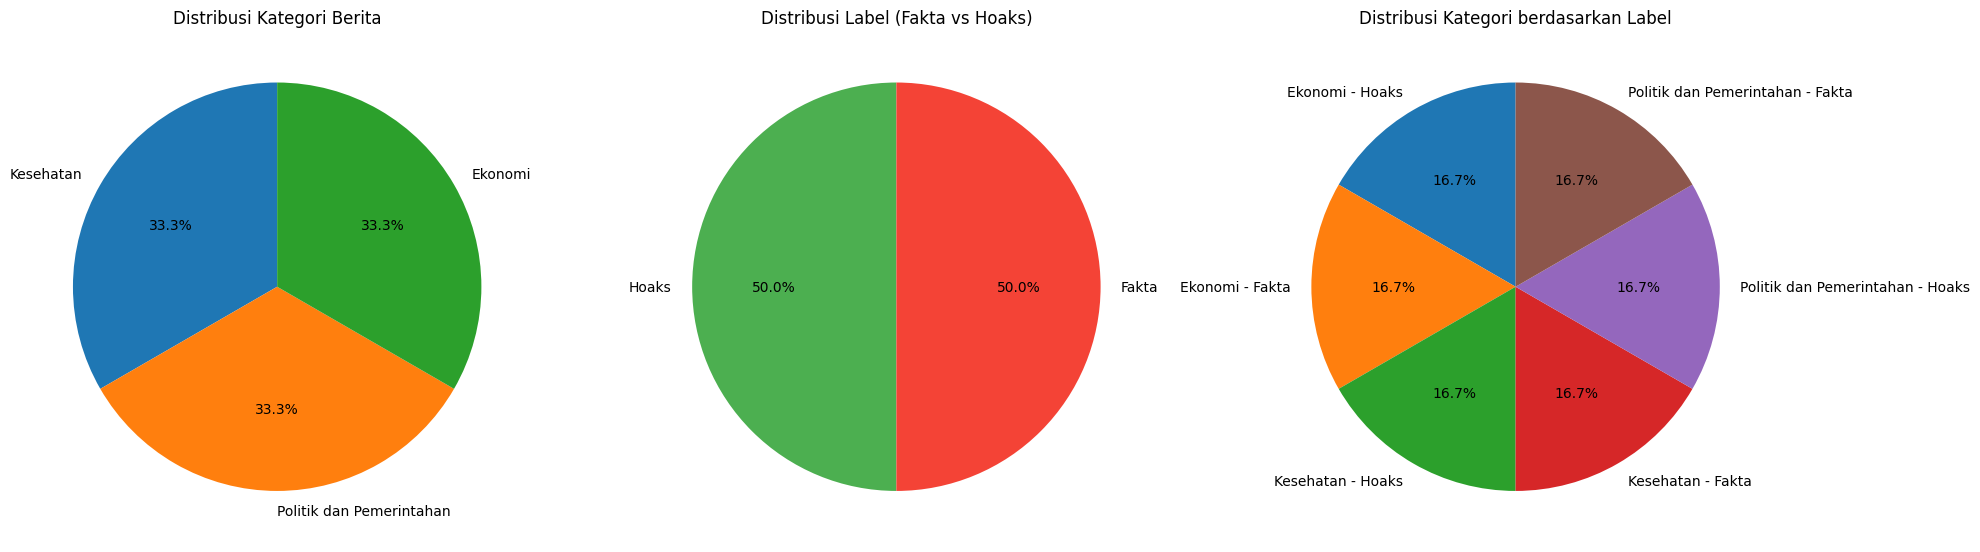

In [ ]:
# ===============================
# NEW FEATURE
# Visualisasi Pie Chart Dataset
# ===============================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Pie Chart 1: Distribusi Kategori
category_counts = merged_df["CATEGORY"].value_counts()
axes[0].pie(category_counts.values, labels=category_counts.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title("Distribusi Kategori Berita")

# Pie Chart 2: Distribusi Label
label_counts = merged_df["LABEL"].map({1: "Fakta", 0: "Hoaks"}).value_counts()
axes[1].pie(label_counts.values, labels=label_counts.index, autopct='%1.1f%%', startangle=90,
            colors=["#4CAF50", "#F44336"])
axes[1].set_title("Distribusi Label (Fakta vs Hoaks)")

# Pie Chart 3: Distribusi Kategori berdasarkan Label (grouped)
combo_counts = merged_df.groupby(["CATEGORY", "LABEL"]).size()
combo_labels = [f"{cat} - {'Fakta' if lbl == 1 else 'Hoaks'}" for cat, lbl in combo_counts.index]
axes[2].pie(combo_counts.values, labels=combo_labels, autopct='%1.1f%%', startangle=90)
axes[2].set_title("Distribusi Kategori berdasarkan Label")

plt.tight_layout()
plt.show()

### Simpan Dataset Final (format: source, url, title, narrative, label, category)

Dataset hasil kategorisasi + balancing (900 per kombinasi kategori x label) disimpan ulang ke
`dataset.csv` dengan nama kolom huruf kecil sesuai format yang diminta. File ini **menimpa**
`dataset.csv` mentah yang sempat disimpan sebelum kategorisasi (di cell Merge Dataset).

In [ ]:
# ===============================
# NEW FEATURE
# Simpan dataset final dengan format kolom:
# source | url | title | narrative | label | category
# ===============================

FINAL_COLUMN_MAP = {
    "SOURCE": "source",
    "URL": "url",
    "TITLE": "title",
    "NARRATIVE": "narrative",
    "LABEL": "label",
    "CATEGORY": "category",
}

dataset_final = merged_df.rename(columns=FINAL_COLUMN_MAP)[list(FINAL_COLUMN_MAP.values())]

dataset_final.to_csv("dataset.csv", index=False, encoding="utf-8-sig")
print(f"[OK] dataset.csv (final, balanced, kolom lowercase) tersimpan: {len(dataset_final)} baris.")
print(f"Kolom: {list(dataset_final.columns)}")
dataset_final.head()


[OK] dataset.csv (final, balanced, kolom lowercase) tersimpan: 5400 baris.
Kolom: ['source', 'url', 'title', 'narrative', 'label', 'category']


,source,url,title,narrative,label,category
0,Komdigi,https://web.komdigi.go.id/api/v1/contents/cate...,[HOAKS] Video Dokter Tirta Menjelaskan Mengena...,Penjelasan :Beredar sebuah unggahan video di m...,0,Kesehatan
1,TurnBackHoax,https://turnbackhoax.id/articles/34994-penipua...,[PENIPUAN] Tautan Pendaftaran Lowongan Kerja B...,Media\n \n ...,0,Kesehatan
2,TurnBackHoax,https://turnbackhoax.id/articles/35161-penipua...,[PENIPUAN] Tautan Pendaftaran Lowongan Kerja P...,Media\n \n ...,0,Kesehatan
3,turnbackhoax.id,https://turnbackhoax.id/articles/33185-salah-m...,[SALAH] Mencium Kucing Mampu Sebabkan Infeksi ...,| TurnBackHoax.ID – Persembahan dari MAFINDO :...,0,Kesehatan
4,TurnBackHoax,https://turnbackhoax.id/articles/34468-salah-v...,[SALAH] Vaksin Campak Sebabkan Autisme Anak,Media\n \n ...,0,Kesehatan


# Hoax Classification Pipeline: IndoBERT + Machine Learning

This notebook implements a professional Machine Learning pipeline for Indonesian hoax classification. We combine state-of-the-art transformer-based feature extraction (**IndoBERT**) with robust traditional classifiers (**SVM**, **Random Forest**, and **Naive Bayes**).

### Project Workflow
1. **Data Cleaning**: Duplicate removal and null handling.
2. **NLP Preprocessing**: Case folding, stopword removal, and stemming using the `Sastrawi` library.
3. **Feature Engineering**: Extracting semantic embeddings using the `indobenchmark/indobert-base-p1` model.
4. **Modeling**: Training and evaluating multiple classifiers to compare performance.
5. **Evaluation**: Detailed metrics including Accuracy, F1-Score, and Precision-Recall.

## 1. Setup & Dependencies

In [3]:
!pip install pandas scikit-learn nltk Sastrawi transformers torch tqdm openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 2.8 MB/s eta 0:00:00


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import torch
import os
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from transformers import AutoTokenizer, AutoModel
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

# Ensure NLTK data is available
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

True

In [5]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
import nltk
import re

class HoaxPreprocessor:
    def __init__(self):
        print("Initializing Sastrawi components...")
        self.stemmer = StemmerFactory().create_stemmer()
        self.stopword_remover = StopWordRemoverFactory().get_stop_words()

    def clean_text(self, text):
        if not isinstance(text, str):
            return ""

        # Case folding
        text = text.lower()
        # Remove URLs, punctuations, and numbers
        text = re.sub(r'http\S+|www.\S+', '', text)
        text = re.sub(r'[^a-z\s]', '', text)
        text = re.sub(r'\s+', ' ', text).strip()

        # Tokenization & Stopword Removal
        tokens = nltk.tokenize.word_tokenize(text)
        tokens = [word for word in tokens if word not in self.stopword_remover]

        # Stemming
        cleaned_text = ' '.join(tokens)
        return self.stemmer.stem(cleaned_text)

    def process_dataframe(self, df, sample_size=None):
        # Drop duplicates and NAs
        df = df.drop_duplicates(subset=['NARRATIVE', 'TITLE']).dropna(subset=['NARRATIVE', 'TITLE', 'LABEL'])

        if sample_size:
            df = df.sample(n=min(sample_size, len(df)), random_state=42).copy()
        else:
            df = df.copy()

        tqdm.pandas(desc="Cleaning Text")
        print("Starting text preprocessing...")
        df['clean_combined'] = (df['TITLE'] + " " + df['NARRATIVE']).progress_apply(self.clean_text)
        return df

In [6]:
def get_embeddings(texts, model_name="indobenchmark/indobert-base-p1", batch_size=16):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)

    # Select Hardware
    device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
    model.to(device)
    model.eval()

    embeddings = []
    for i in tqdm(range(0, len(texts), batch_size), desc="Extracting Features"):
        batch = texts[i:i+batch_size].tolist()
        inputs = tokenizer(batch, padding=True, truncation=True, max_length=512, return_tensors='pt').to(device)

        with torch.no_grad():
            outputs = model(**inputs)

        # Mean Pooling
        mask = inputs['attention_mask'].unsqueeze(-1).expand(outputs.last_hidden_state.size()).float()
        sum_embeddings = torch.sum(outputs.last_hidden_state * mask, 1)
        sum_mask = torch.clamp(mask.sum(1), min=1e-9)
        mean_pooled = (sum_embeddings / sum_mask).cpu().numpy()
        embeddings.append(mean_pooled)

    return np.vstack(embeddings)

In [ ]:
DATA_PATH = 'dataset.csv'
SAMPLE_SIZE = None # Set to None for full dataset

if not os.path.exists(DATA_PATH):
    print(f"Dataset not found! Please ensure '{DATA_PATH}' is in the current directory.")
else:
    # 1. Load
    df_raw = pd.read_csv(DATA_PATH)

    # ===============================
    # NEW FEATURE (compatibility fix)
    # dataset.csv sekarang disimpan dengan kolom huruf kecil
    # (source, url, title, narrative, label, category) sesuai format yang
    # diminta. Baris ini menyesuaikan ke huruf besar supaya seluruh
    # pipeline preprocessing/training di bawah (yang memakai
    # TITLE/NARRATIVE/LABEL/CATEGORY) TIDAK PERLU diubah sama sekali.
    # ===============================
    df_raw.columns = [c.upper() for c in df_raw.columns]

    # 2. Preprocess
    preprocessor = HoaxPreprocessor()
    df_clean = preprocessor.process_dataframe(df_raw, sample_size=SAMPLE_SIZE)

    # 3. Features
    X = get_embeddings(df_clean['clean_combined'])
    y = df_clean['LABEL'].values

    # ===============================
    # NEW FEATURE
    # Teks asli (aligned dengan X/y lewat train_test_split yang sama) --
    # dibutuhkan nanti untuk mengevaluasi OUTPUT AKHIR seluruh pipeline
    # (Category Validation Gate -> SVM -> GPT), bukan cuma classifier SVM saja.
    # Proses embedding X di atas TIDAK diubah sama sekali.
    # ===============================
    text_for_pipeline = df_clean['NARRATIVE'].values

    # 4. Train/Test Split
    X_train, X_test, y_train, y_test, text_train, text_test = train_test_split(
        X, y, text_for_pipeline, test_size=0.1, random_state=42
    )

    print(f"\nData split complete. Training on {len(X_train)} samples, testing on {len(X_test)} samples.")

Initializing Sastrawi components...
Starting text preprocessing...


Cleaning Text:   0%|          | 0/4740 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Extracting Features:   0%|          | 0/297 [00:00<?, ?it/s]


Data split complete. Training on 4266 samples, testing on 474 samples.



--- Training SVM (Linear) ---
Accuracy: 0.9958
F1-Score (Weighted): 0.9958
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       189
           1       0.99      1.00      1.00       285

    accuracy                           1.00       474
   macro avg       1.00      0.99      1.00       474
weighted avg       1.00      1.00      1.00       474



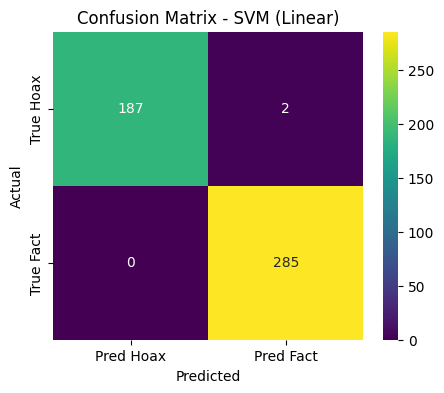

In [ ]:
models = {
    "SVM (Linear)": SVC(kernel='linear', probability=True),
}

for name, model in models.items():
    print(f"\n--- Training {name} ---")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"F1-Score (Weighted): {f1_score(y_test, y_pred, average='weighted'):.4f}")
    print(classification_report(y_test, y_pred))

     # Visualize results with Confusion Matrix
    plt.figure(figsize=(5,4))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis',
                xticklabels=["Pred Hoax", "Pred Fact"],
                yticklabels=["True Hoax", "True Fact"])
    # ===============================
    # BUGFIX (existing code, not new): variable "model_name" was undefined here;
    # corrected to use the loop variable "name". The Confusion Matrix (requirement)
    # already existed in this cell, it was just broken -> now fixed.
    # ===============================
    plt.title(f"Confusion Matrix - {name}")
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

In [ ]:
import joblib

# Save the best performing model (e.g., SVM)
svm_model = models["SVM (Linear)"]
joblib.dump(svm_model, 'svm_model.pkl')
print("SVM model saved as svm_model.pkl")


SVM model saved as svm_model.pkl


In [7]:
def predict_hoax(text: str, models: dict, preprocessor: HoaxPreprocessor, tokenizer, model_bert) -> dict:
    """Predicts if a given text is a hoax using all trained models."""
    clean_text_input = preprocessor.clean_text(text)

    # Get embedding for the input text
    device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
    model_bert.to(device)
    model_bert.eval()

    inputs = tokenizer([clean_text_input], padding=True, truncation=True, max_length=512, return_tensors='pt').to(device)

    with torch.no_grad():
        outputs = model_bert(**inputs)

    mask = inputs['attention_mask'].unsqueeze(-1).expand(outputs.last_hidden_state.size()).float()
    sum_embeddings = torch.sum(outputs.last_hidden_state * mask, 1)
    sum_mask = torch.clamp(mask.sum(1), min=1e-9)
    embedding = (sum_embeddings / sum_mask).cpu().numpy()

    predictions = {}
    for name, ml_model in models.items():
        pred = ml_model.predict(embedding)[0]
        predictions[name] = "Hoax" if pred == 0 else "Fact"

    return predictions

In [9]:
from transformers import AutoTokenizer, AutoModel

# Load tokenizer and model for embeddings once
bert_model_name = "indobenchmark/indobert-base-p1"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_model_name)
bert_model = AutoModel.from_pretrained(bert_model_name)

# Instantiate the preprocessor (if not already done)
if 'preprocessor' not in locals():
    preprocessor = HoaxPreprocessor()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [20]:
import joblib
loaded_svm_model = joblib.load('svm_model.pkl')
print("SVM model loaded successfully.")

SVM model loaded successfully.


In [21]:
test_models = {"Loaded SVM": loaded_svm_model}
sample_text_for_test = "Pemerintah akan membagikan bantuan sosial tunai sebesar 1 juta rupiah kepada seluruh warga." # Replace with your test text
print(f"\nPredicting for text: '{sample_text_for_test}'")
predictions_with_loaded_model = predict_hoax(sample_text_for_test, test_models, preprocessor, bert_tokenizer, bert_model)

for model_name, prediction in predictions_with_loaded_model.items():
    print(f"  {model_name}: {prediction}")


Predicting for text: 'Pemerintah akan membagikan bantuan sosial tunai sebesar 1 juta rupiah kepada seluruh warga.'
  Loaded SVM: Fact


# Fetch Sample From X.com

In [22]:
import requests
from bs4 import BeautifulSoup

LINK_BERITA = "https://x.com/hariankompas/status/2076470359759757541"

response = requests.get(
    LINK_BERITA,
    headers={"User-Agent": "Mozilla/5.0"}
)

soup = BeautifulSoup(response.text, 'html.parser')

if soup.title:
    narative_sample = soup.title.text
else:
    narative_sample = """
    Bripda AS resmi jadi tersangka atas kematian rekan polisi
    yang dianiaya di barak Polda Kepri.
    """

print(narative_sample)

Harian Kompas on X: "Selamat pagi Sahabat Kompas. 

Berita hari ini: Komisi Kejaksaan menilai kasus bekas Jampidsus Febrie Adriansyah mengungkap adanya celah pengawasan di internal Kejagung, Presiden Prabowo menargetkan Koperasi Desa Merah Putih meningkatkan perputaran uang Rp 223 triliun per tahun di desa, belajar revolusi sepak bola ala Maroko dan praktik bahasa isyarat. 

Baca selengkapnya di https://t.co/KZ58AEx3Xf

#Polhuk #Ekonomi #Kompas61" / X


### Sample Hoax and Fact Articles for Testing

In [23]:
import joblib
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

# Load all trained models
models = {
    "SVM (Linear)": joblib.load('svm_model.pkl'),
}

test_narative_sample = predict_hoax(narative_sample, models, preprocessor, bert_tokenizer, bert_model)
for model_name, prediction in test_narative_sample.items():
    print(f"  {model_name}: {prediction}")

  SVM (Linear): Fact


In [ ]:
import openai
import os

openai_api_key = ""

if openai_api_key:
    openai.api_key = openai_api_key
    print("OpenAI API key loaded.")
else:
    print("Warning: OpenAI API key not found. Please set it in Colab secrets or environment variables.")

OpenAI API key loaded.


In [25]:
def predict_hoax_openai(text: str, category: str = None, svm_prediction: str = None) -> dict:
    """Predicts if a given text is a hoax or fact, including news category analysis."""

    if not openai.api_key:
        return {"error": "OpenAI API key is not set."}

    # Add category and SVM prediction to the prompt if available
    context_info = ""
    if category:
        context_info += f"Kategori hasil deteksi awal: {category}.\n"
    if svm_prediction:
        context_info += f"Prediksi hoaks/fakta dari model SVM: {svm_prediction}.\n\n"

    prompt_template = f"""
Anda adalah asisten AI untuk deteksi hoaks dan analisis berita.

{context_info}

Tugas Anda:
1. Tentukan apakah berita termasuk:
   - Hoaks
   - Fakta

2. Tentukan kategori berita yang paling sesuai, misalnya:
   - Politik
   - Ekonomi
   - Teknologi
   - Kesehatan
   - Pendidikan
   - Olahraga
   - Hiburan
   - Kriminal
   - Sosial
   - Internasional
   - Lingkungan
   - Lainnya

3. Berikan tingkat kepercayaan prediksi dalam persen.

4. Jika berita termasuk "Fakta":
   - Berikan penjelasan singkat
   - Berikan minimal 2 tautan sumber terpercaya yang relevan

5. Jika berita termasuk "Hoaks":
   - Berikan alasan mengapa berita tersebut terindikasi hoaks
   - Sebutkan ciri-ciri misinformasi/disinformasi jika ada

Format jawaban WAJIB seperti berikut:

Klasifikasi: [Hoaks/Fakta]

Kategori: [Kategori Berita]

Tingkat Kepercayaan: [0-100]%

Penjelasan:
[Penjelasan singkat]

Ciri-Ciri Hoaks:
- [Poin 1]
- [Poin 2]

Tautan Pendukung:
1. [Link 1]
2. [Link 2]

Berikut teks berita yang harus dianalisis:
{text}
"""

    try:
        response = openai.chat.completions.create(
            model="gpt-3.5-turbo",
            messages=[
                {
                    "role": "system",
                    "content": (
                        "You are a professional hoax detection and news classification assistant. "
                        "Analyze news carefully, classify the category, and provide accurate explanations."
                    )
                },
                {
                    "role": "user",
                    "content": prompt_template
                }
            ],
            temperature=0.2,
            max_completion_tokens=700
        )

        return response.choices[0].message.content

    except Exception as e:
        return {"error": f"Error calling OpenAI API: {e}"}

In [26]:
print("--- Testing Narative Sample From X.COM ---")
openai_results_narative = predict_hoax_openai(narative_sample)
print(openai_results_narative)

--- Testing Narative Sample From X.COM ---
Klasifikasi: Fakta

Kategori: Politik, Ekonomi

Tingkat Kepercayaan: 100%

Penjelasan:
Berita tersebut merupakan fakta yang mencakup informasi tentang penilaian Komisi Kejaksaan terhadap kasus bekas Jampidsus Febrie Adriansyah, target Presiden Prabowo terkait Koperasi Desa Merah Putih, serta pembelajaran revolusi sepak bola ala Maroko dan praktik bahasa isyarat.

Tautan Pendukung:
1. https://www.kompas.com/
2. [Tautan lainnya dari Kompas]

Berita tersebut dapat dipercaya karena berasal dari sumber terpercaya dan tidak menunjukkan ciri-ciri hoaks atau misinformasi.


### Category Validation Gate + Full Multilayer Pipeline

Alur: **Preprocessing -> Embedding IndoBERT -> Klasifikasi Kategori -> (jika valid) -> Multilayer Hoax Detection (IndoBERT+SVM, GPT Explainable AI) -> Output**.

Jika kategori berita di luar Kesehatan / Politik dan Pemerintahan / Ekonomi, proses dihentikan **sebelum** masuk ke model SVM maupun GPT Analysis. Fungsi multilayer yang sudah ada (`predict_hoax`, `predict_hoax_openai`) TIDAK diubah, hanya dipanggil di sini secara berurutan.

In [27]:
import re

# ==========================================================
# Pesan penolakan
# ==========================================================

REJECTION_MESSAGE = """
Maaf, sistem hanya dapat mendeteksi berita pada kategori:

✓ Kesehatan
✓ Politik dan Pemerintahan
✓ Ekonomi

Silakan masukkan berita yang termasuk salah satu kategori tersebut.
"""

# ==========================================================
# Weighted Keywords
# ==========================================================

HEALTH_PRIMARY = {
    "kesehatan":5,
    "rumah sakit":5,
    "puskesmas":5,
    "dokter":5,
    "dokter spesialis":5,
    "perawat":5,
    "pasien":5,
    "vaksin":5,
    "vaksinasi":5,
    "imunisasi":5,
    "covid":5,
    "covid-19":5,
    "virus":5,
    "penyakit":5,
    "wabah":5,
    "epidemi":5,
    "pandemi":5,
    "obat":5,
    "farmasi":5,
    "bpjs":5,
    "bpjs kesehatan":5,
    "kemenkes":5,
    "menteri kesehatan":5,
    "tenaga kesehatan":5,
    "dokter umum":5,
    "dokter gigi":5,
    "dokter anak":5,
    "dokter paru":5,
    "dokter jantung":5,
    "dokter kandungan":5,
    "dokter penyakit dalam":5,
    "dokter saraf":5,
    "dokter mata":5,
    "dokter kulit":5,
    "dokter tht":5,
    "dokter bedah":5,
    "dokter jiwa":5,
    "bidan":5,
    "apoteker":5,
    "paramedis":5,
    "nakes":5,
    "tenaga medis":5,
    "petugas kesehatan":5,
    "faskes":5,
    "dinas kesehatan":5,
    "kementerian kesehatan":5,
    "alat kesehatan":5,
    "alkes":5,
    "pengobatan":5,
    "diagnosis":5,
    "terapi":5,
    "rehabilitasi":5,
    "rawat intensif":5,
    "icu":5,
    "nicu":5,
    "karantina":5,
    "isolasi":5,
    "penularan":5,
    "infeksi":5,
    "medical check up":5,
    "cek kesehatan":5,
    "pemeriksaan kesehatan":5,
    "obat resep":5,
    "obat keras":5,
    "obat bebas":5,
    "epidemiologi":5,
    "kesehatan masyarakat":5,
    "pelayanan medis":5,
    "pelayanan rumah sakit":5,
    "donor darah":5,
    "transfusi darah":5,
    "cuci darah":5,
    "hemodialisa":5,
    "imunitas":5,
    "imun":5,
    "vaksin booster":5,
    "demam berdarah dengue":5,
    "covid panjang":5,
    "long covid":5,
    "covid varian":5,
    "omicron":5,
    "delta":5,
    "tetanus":5,
    "difteri":5,
    "pertusis":5,
    "rubella":5,
    "gondongan":5,
    "campak":5,
    "polio":5,
    "rabies":5,
    "antraks":5,
    "kolera":5,
    "pes":5,
    "chikungunya":5,
    "zika":5,
    "ebola":5,
    "hiv":5,
    "aids":5,
    "infeksi hiv":5,
    "tifus":5,
    "tifoid":5,
    "demam tifoid":5,
    "leptospirosis":5,
    "filariasis":5,
    "kusta":5,
    "toksoplasma":5
}

HEALTH_SECONDARY = {
    "klinik":3,
    "rawat inap":3,
    "rawat jalan":3,
    "igd":3,
    "ambulans":3,
    "gizi":3,
    "stunting":3,
    "demam":3,
    "flu":3,
    "dbd":3,
    "malaria":3,
    "tbc":3,
    "hepatitis":3,
    "diabetes":3,
    "hipertensi":3,
    "kanker":3,
    "operasi":3,
    "bedah":3,
    "laboratorium":3,
    "tes kesehatan":3,
    "rapid test":3,
    "pcr":3,
    "skrining":3,
    "resep":3,
    "apotek":3,
    "nutrisi":3,
    "psikologi":3,
    "kesehatan mental":3,
    "dna":3,
    "batuk":3,
    "pilek":3,
    "sesak napas":3,
    "asma":3,
    "bronkitis":3,
    "pneumonia":3,
    "radang paru":3,
    "stroke":3,
    "serangan jantung":3,
    "jantung":3,
    "paru":3,
    "ginjal":3,
    "hati":3,
    "otak":3,
    "kolesterol":3,
    "asam urat":3,
    "obesitas":3,
    "anemia":3,
    "campak":3,
    "polio":3,
    "tifus":3,
    "rabies":3,
    "cacar":3,
    "cacar air":3,
    "flu burung":3,
    "flu babi":3,
    "demam berdarah":3,
    "leptospirosis":3,
    "tumor":3,
    "osteoporosis":3,
    "epilepsi":3,
    "autisme":3,
    "ibu hamil":3,
    "kehamilan":3,
    "persalinan":3,
    "janin":3,
    "bayi":3,
    "balita":3,
    "anak":3,
    "remaja":3,
    "lansia":3,
    "vitamin":3,
    "mineral":3,
    "protein":3,
    "kalori":3,
    "suplemen":3,
    "sanitasi":3,
    "higiene":3,
    "air bersih":3,
    "pola hidup sehat":3,
    "olahraga":3,
    "kebugaran":3,
    "bpom":3,
    "uji klinis":3,
    "uji laboratorium":3,
    "hasil laboratorium":3,
    "rujukan":3,
    "infus":3,
    "oksigen":3,
    "ventilator":3,
    "masker":3,
    "alat pelindung diri":3,
    "psikiater":3,
    "psikolog":3,
    "depresi":3,
    "stres":3,
    "gangguan mental":3,
    "nutrisi seimbang":3,
    "gizi buruk":3,
    "kurang gizi":3,
    "gizi anak":3,
    "kadar gula":3,
    "tekanan darah":3,
    "detak jantung":3,
    "paru":3,
    "paru-paru":3,
    "jantung":3,
    "ginjal":3,
    "hati":3,
    "liver":3,
    "usus":3,
    "lambung":3,
    "empedu":3,
    "limpa":3,
    "pankreas":3,
    "otak":3,
    "saraf":3,
    "mata":3,
    "retina":3,
    "kornea":3,
    "telinga":3,
    "hidung":3,
    "tenggorokan":3,
    "mulut":3,
    "gigi":3,
    "kulit":3,
    "tulang":3,
    "sendi":3,
    "otot":3
}

HEALTH_PHRASE = {
    "pelayanan kesehatan":7,
    "program vaksinasi":7,
    "fasilitas kesehatan":7,
    "rumah sakit daerah":7,
    "rumah sakit umum":7,
    "tenaga medis":7,
    "tenaga kesehatan":7,
    "menteri kesehatan":7,
    "bpjs kesehatan":7,
    "dinas kesehatan":7,
    "kartu indonesia sehat":7,
    "rumah sakit swasta":7,
    "rumah sakit pemerintah":7,
    "rumah sakit nasional":7,
    "rumah sakit vertikal":7,
    "rumah sakit pendidikan":7,
    "rumah sakit rujukan":7,
    "pelayanan medis":7,
    "layanan kesehatan":7,
    "pelayanan rumah sakit":7,
    "pelayanan pasien":7,
    "tenaga kesehatan indonesia":7,
    "program kesehatan":7,
    "program imunisasi":7,
    "program pencegahan penyakit":7,
    "program skrining":7,
    "program kesehatan nasional":7,
    "kementerian kesehatan republik indonesia":7,
    "dinas kesehatan provinsi":7,
    "dinas kesehatan kabupaten":7,
    "dinas kesehatan kota":7,
    "cek kesehatan gratis":7,
    "pemeriksaan kesehatan gratis":7,
    "medical check up":7,
    "alat pelindung diri":7,
    "alat kesehatan":7,
    "kesehatan ibu dan anak":7,
    "ibu dan bayi":7,
    "gizi seimbang":7,
    "kesehatan masyarakat":7,
    "kesehatan mental":7,
    "pengendalian penyakit":7,
    "penyakit menular":7,
    "penyakit tidak menular":7,
    "vaksin covid":7,
    "program vaksin covid":7,
    "vaksin booster":7,
    "bpjs kesehatan":7,
    "peserta bpjs":7,
    "klaim bpjs":7,
    "rawat inap":7,
    "rawat jalan":7,
    "unit gawat darurat":7,
    "instalasi gawat darurat":7,
    "intensive care unit":7,
    "operasi jantung":7,
    "operasi caesar":7,
    "transplantasi organ":7,
    "program cek kesehatan gratis":7,
    "cek kesehatan gratis":7,
    "kementerian kesehatan republik indonesia":7,
    "organisasi kesehatan dunia":7,
    "pelayanan kesehatan masyarakat":7,
    "pusat kesehatan masyarakat":7,
    "fasilitas pelayanan kesehatan":7,
    "tenaga kesehatan indonesia":7,
    "rumah sakit umum daerah":7,
    "rumah sakit umum pusat":7,
    "rumah sakit rujukan nasional":7,
    "penyakit menular":7,
    "penyakit tidak menular":7,
    "vaksin covid 19":7,
    "program imunisasi nasional":7,
    "program vaksinasi nasional":7,
    "alat pelindung diri":7,
    "gizi ibu dan anak":7,
    "kesehatan ibu dan anak":7,
    "pelayanan rawat inap":7,
    "pelayanan rawat jalan":7,
    "unit gawat darurat":7,
    "instalasi gawat darurat":7,
    "intensive care unit":7
}

POLITICAL_PRIMARY = {
    "presiden":10,
    "wakil presiden":10,
    "dpr":10,
    "mpr":5,
    "dpd":10,
    "kpu":10,
    "bawaslu":5,
    "pemilu":5,
    "pilkada":5,
    "pilpres":5,
    "menteri":10,
    "kabinet":10,
    "pemerintah":10,
    "pemerintahan":10,
    "undang-undang":5,
    "peraturan":5,
    "keputusan presiden":5,
    "kemendagri":5,
    "mahkamah konstitusi":5,
    "mahkamah agung":5,
    "prabowo":5,
    "gibran":5,
    "istana":5,
    "istana negara":5,
    "politik":5,
    "demokrasi":5,
    "negara":5,
    "konstitusi":5,
    "uud":5,
    "uud 1945":5,
    "perpu":5,
    "perpres":5,
    "peraturan presiden":5,
    "peraturan pemerintah":5,
    "peraturan daerah":5,
    "keputusan menteri":5,
    "keputusan gubernur":5,
    "keputusan bupati":5,
    "keputusan wali kota":5,
    "legislatif":5,
    "eksekutif":5,
    "yudikatif":5,
    "kementerian":5,
    "lembaga negara":5,
    "sekretariat negara":5,
    "sekretariat kabinet":5,
    "asn":5,
    "aparatur sipil negara":5,
    "pegawai negeri":5,
    "pns":5,
    "hak suara":5,
    "pemilih":5,
    "pemungutan suara":5,
    "tps":5,
    "caleg":5,
    "calon gubernur":5,
    "calon bupati":5,
    "calon wali kota":5,
    "calon wakil presiden":5,
    "dprd":5,
    "komisi":5,
    "fraksi":5,
    "kementerian dalam negeri":5,
    "kementerian luar negeri":5,
    "kementerian hukum":5,
    "putusan mk":5,
    "putusan ma":5,
    "hak angket":5,
    "hak interpelasi":5,
    "kabinet merah putih":5,
    "istana kepresidenan":5,
    "istana merdeka":5,
    "wakil menteri":5,
    "staf presiden":5,
    "staf khusus presiden":5,
    "sekretaris negara":5,
    "sekretaris kabinet":5,
    "kementerian sekretariat negara":5,
    "kabinet indonesia":5,
    "kabinet indonesia maju":5,
    "kabinet merah putih":5,
    "dprd provinsi":5,
    "dprd kabupaten":5,
    "dprd kota":5,
    "kpk":5,
    "kejaksaan agung":5,
    "kejaksaan negeri":5,
    "kejaksaan tinggi":5,
    "kepolisian":5,
    "polri":5,
    "tni":5,
    "tni ad":5,
    "tni al":5,
    "tni au":5,
    "bin":5,
    "bnpb":5,
    "ombudsman":5,
    "bpk":5,
    "bpkp":5,
    "ky":5,
    "komnas ham":5,
    "hakim":5,
    "jaksa":5,
    "pengadilan":5,
    "pengadilan negeri":5,
    "pengadilan tinggi":5,
    "pengadilan tata usaha negara":5,
    "gubernur bank indonesia":5,
    "duta besar":5,
    "kedutaan":5,
    "diplomat":5,
    "pemimpin negara":5,
    "kepala negara":5,
    "kepala pemerintahan":5,
    "anggota kabinet":5,
    "kabinet kerja":5,
    "rapat kabinet":5,
    "politik luar negeri":5,
    "politik dalam negeri":5,
    "hak veto":5,
    "referendum":5,
    "koalisi pemerintah":5,
    "pemilu serentak":5,
    "pilkada serentak":5
}

POLITICAL_SECONDARY = {
    "fraksi":3,
    "sidang":3,
    "rapat":3,
    "koalisi":3,
    "oposisi":3,
    "anggota dewan":3,
    "partai":3,
    "gubernur":3,
    "bupati":3,
    "wali kota":3,
    "otonomi daerah":3,
    "anggota legislatif":3,
    "hak pilih":3,
    "pemungutan suara":3,
    "kampanye":3,
    "calon presiden":3,
    "calon kepala daerah":3,
    "jokowi":3,
     "voting":3,
    "debat":3,
    "debat capres":3,
    "debat pilkada":3,
    "visi misi":3,
    "manifesto":3,
    "parlemen":3,
    "anggota dpr":3,
    "anggota mpr":3,
    "anggota dpd":3,
    "anggota dprd":3,
    "kepala daerah":3,
    "wakil gubernur":3,
    "wakil bupati":3,
    "wakil wali kota":3,
    "pemda":3,
    "sekda":3,
    "birokrasi":3,
    "rapat kerja":3,
    "rapat dengar pendapat":3,
    "komisi dpr":3,
    "komisi i":3,
    "komisi ii":3,
    "komisi iii":3,
    "komisi iv":3,
    "komisi v":3,
    "koalisi partai":3,
    "oposisi":3,
    "judicial review":3,
    "uji materi":3,
    "pelantikan":3,
    "reshuffle":3,
    "reshuffle kabinet":3,
    "surat suara":3,
    "kotak suara":3,
    "daftar pemilih":3,
    "dpt":3,
    "pemilih tetap":3,
    "kampanye terbuka":3,
    "kampanye akbar":3,
    "kampanye damai":3,
    "kampanye hitam":3,
    "politik uang":3,
    "money politics":3,
    "hak konstitusi":3,
    "hak warga negara":3,
    "otonomi khusus":3,
    "desentralisasi":3,
    "sentralisasi":3,
    "musyawarah":3,
    "mufakat":3,
    "lobi politik":3,
    "revisi uu":3,
    "amandemen":3,
    "lobi politik":3,
    "negosiasi politik":3,
    "elite politik":3,
    "elit politik":3,
    "opini politik":3,
    "isu politik":3,
    "dinamika politik":3,
    "konstelasi politik":3,
    "stabilitas politik":3,
    "krisis politik":3,
    "politik identitas":3,
    "politik uang":3,
    "money politics":3,
    "serangan fajar":3,
    "debat publik":3,
    "debat calon":3,
    "debat pasangan calon":3,
    "surat suara":3,
    "kotak suara":3,
    "bilik suara":3,
    "petugas kpps":3,
    "kpps":3,
    "pps":3,
    "ppk":3,
    "dpt":3,
    "dptb":3,
    "dpk":3,
    "rekapitulasi suara":3,
    "penghitungan suara":3,
    "quick count":3,
    "real count":3,
    "saksi pemilu":3,
    "pengawas pemilu":3,
    "calon independen":3,
    "partai politik":3,
    "ketua umum":3,
    "sekretaris jenderal":3,
    "sekjen":3,
    "anggaran negara":3,
    "sidang pleno":3,
    "sidang istimewa":3,
    "hak angket":3,
    "hak interpelasi":3,
    "hak menyatakan pendapat":3,
    "revisi undang undang":3,
    "rancangan undang undang":3,
    "ruu":3,
    "voting":3,
    "pemungutan suara elektronik":3,
    "masa jabatan":3,
    "pelantikan pejabat":3,
    "mutasi pejabat":3,
    "rotasi pejabat":3,
    "calon legislatif":3,
    "caleg":3,
    "capres":3,
    "cawapres":3,
    "cakada":3,
    "putusan hakim":3,
    "putusan pengadilan":3,
    "sidang mk":3,
    "sidang ma":3,
    "hak konstitusional":3,
    "uji materi":3,
    "judicial review":3,
    "birokrasi":3,
    "reformasi birokrasi":3,
    "otonomi khusus":3,
    "desentralisasi":3,
    "sentralisasi":3,
    "diplomasi":3,
    "hubungan bilateral":3,
    "hubungan internasional":3,
    "kerja sama internasional":3,
    "mosi":3,
    "interupsi":3,
    "musyawarah":3,
    "mufakat":3
}

POLITICAL_PHRASE = {
    "pemilihan umum":7,
    "rapat kabinet":7,
    "sidang paripurna":7,
    "dewan perwakilan rakyat":7,
    "mahkamah konstitusi":7,
    "komisi pemilihan umum":7,
    "badan pengawas pemilu":7,
    "presiden republik indonesia":7,
    "kementerian dalam negeri":7,
    "undang undang":7,
    "pemilihan kepala daerah":7,
    "pemilihan gubernur":7,
    "pemilihan bupati":7,
    "pemilihan wali kota":7,
    "pemilihan presiden":7,
    "pemilihan legislatif":7,
    "pemungutan suara ulang":7,
    "hasil pemilu":7,
    "hasil pilkada":7,
    "hasil pilpres":7,
    "rapat kerja dpr":7,
    "rapat dengar pendapat":7,
    "rapat komisi":7,
    "mahkamah agung republik indonesia":7,
    "mahkamah konstitusi republik indonesia":7,
    "komisi pemilihan umum republik indonesia":7,
    "badan pengawas pemilu republik indonesia":7,
    "dewan perwakilan daerah":7,
    "dewan perwakilan rakyat daerah":7,
    "presiden republik indonesia":7,
    "wakil presiden republik indonesia":7,
    "sekretariat kabinet republik indonesia":7,
    "sekretariat negara republik indonesia":7,
    "kementerian hukum":7,
    "kementerian dalam negeri republik indonesia":7,
    "kementerian luar negeri republik indonesia":7,
    "hak asasi manusia":7,
    "hak warga negara":7,
    "undang undang dasar":7,
    "undang undang dasar 1945":7,
    "peraturan pemerintah":7,
    "peraturan presiden":7,
    "peraturan daerah":7,
    "sidang kabinet":7,
    "sidang pleno":7,
    "sidang mahkamah konstitusi":7,
    "sidang mahkamah agung":7,
    "pemilu serentak":7,
    "pilkada serentak":7,
    "calon presiden":7,
    "calon wakil presiden":7,
    "kepala daerah":7,
    "wakil kepala daerah":7,
    "aparatur sipil negara":7,
    "pegawai negeri sipil":7,
    "keputusan presiden":7,
    "keputusan menteri":7,
    "kabinet indonesia":7,
    "kabinet merah putih":7,
    "istana negara republik indonesia":7,
    "dewan perwakilan rakyat republik indonesia":7,
    "dewan perwakilan daerah republik indonesia":7,
    "majelis permusyawaratan rakyat republik indonesia":7,
    "komisi pemberantasan korupsi":7,
    "kepolisian republik indonesia":7,
    "tentara nasional indonesia":7,
    "kejaksaan agung republik indonesia":7,
    "komisi yudisial republik indonesia":7,
    "badan pemeriksa keuangan":7,
    "ombudsman republik indonesia":7,
    "kementerian sekretariat negara":7,
    "sekretariat kabinet republik indonesia":7,
    "kementerian luar negeri republik indonesia":7,
    "kementerian pertahanan republik indonesia":7,
    "kementerian hukum republik indonesia":7,
    "pemilihan kepala daerah serentak":7,
    "pemilihan legislatif":7,
    "pemilihan presiden republik indonesia":7,
    "penghitungan suara nasional":7,
    "rekapitulasi hasil pemilu":7,
    "rekapitulasi suara nasional":7,
    "putusan mahkamah konstitusi":7,
    "putusan mahkamah agung":7,
    "hak asasi manusia":7,
    "hak konstitusional warga negara":7,
    "rancangan undang undang":7,
    "peraturan pemerintah pengganti undang undang":7,
    "rapat kerja komisi":7,
    "rapat dengar pendapat umum":7,
    "sidang tahunan mpr":7,
    "sidang bersama dpr dan dpd":7,
    "pegawai negeri sipil":7,
    "aparatur sipil negara":7,
    "politik luar negeri indonesia":7,
    "politik dalam negeri indonesia":7,
    "hubungan diplomatik indonesia":7,
    "hubungan bilateral indonesia":7,
    "pemungutan suara ulang":7,
    "tempat pemungutan suara":7,
    "kabinet republik indonesia":7,
    "kabinet merah putih":7,
    "istana kepresidenan republik indonesia":7,
    "gubernur provinsi":7,
    "bupati kabupaten":7,
    "wali kota":7,
    "kepala daerah":7,
    "wakil kepala daerah":7,
    "komisi pemilihan umum republik indonesia":7,
    "badan pengawas pemilu republik indonesia":7
}

ECONOMY_PRIMARY = {
    "ekonomi":5,
    "inflasi":5,
    "deflasi":5,
    "bank":5,
    "bank indonesia":5,
    "bi rate":5,
    "suku bunga":5,
    "nilai tukar":5,
    "rupiah":5,
    "dolar":5,
    "investasi":5,
    "pajak":5,
    "bea cukai":5,
    "anggaran":5,
    "apbn":5,
    "apbd":5,
    "perdagangan":5,
    "ekspor":5,
    "impor":5,
    "industri":5,
    "umkm":5,
    "pasar":5,
    "tunai":5,
    "purbaya":5,
    "kartu debit":5,
    "menkeu":5,
    "transfer":5,
     "keuangan":5,
    "moneter":5,
    "fiskal":5,
    "makroekonomi":5,
    "mikroekonomi":5,
    "bank sentral":5,
    "bank syariah":5,
    "bank umum":5,
    "bank bumn":5,
    "bank digital":5,
    "ojk":5,
    "otoritas jasa keuangan":5,
    "lps":5,
    "bank indonesia":5,
    "kementerian keuangan":5,
    "menteri keuangan":5,
    "dirjen pajak":5,
    "ditjen pajak":5,
    "djp":5,
    "bea masuk":5,
    "bea keluar":5,
    "ppn":5,
    "pph":5,
    "pajak kendaraan":5,
    "pajak bumi":5,
    "pajak daerah":5,
    "penerimaan negara":5,
    "belanja negara":5,
    "apbn":5,
    "apbd":5,
    "investor":5,
    "investasi asing":5,
    "penanaman modal":5,
    "modal":5,
    "perusahaan":5,
    "korporasi":5,
    "bumn":5,
    "bumd":5,
    "pasar modal":5,
    "emiten":5,
    "bursa efek":5,
    "bei":5,
    "obligasi negara":5,
    "surat utang":5,
    "sbn":5,
    "sukuk":5,
    "likuiditas":5,
    "kredit":5,
    "kredit usaha rakyat":5,
    "kur":5,
    "pinjaman online":5,
    "pinjol":5,
    "fintech":5,
    "dompet digital":5,
    "e-wallet":5,
    "qris":5,
    "neraca perdagangan":5,
    "surplus":5,
    "defisit":5,
    "komoditas":5,
    "perkebunan":5,
    "pertanian":5,
    "perikanan":5,
    "peternakan":5,
    "energi":5,
    "minyak":5,
    "gas":5,
    "lpg":5,
    "properti":5,
    "real estate":5,
    "ritel":5,
    "grosir":5,
    "distribusi":5,
    "ekspor impor":5,
    "perdagangan internasional":5,
    "nilai ekspor":5,
    "nilai impor":5
}

ECONOMY_SECONDARY = {
    "harga":3,
    "harga pangan":3,
    "harga beras":3,
    "harga minyak":3,
    "harga bbm":3,
    "subsidi":3,
    "pertumbuhan ekonomi":3,
    "bursa":3,
    "ihsg":3,
    "saham":3,
    "obligasi":3,
    "dividen":3,
    "usaha":3,
    "bisnis":3,
    "pendapatan":3,
    "kemiskinan":3,
    "pengangguran":3,
    "daya beli":3,
    "koperasi":3,
    "perbankan":3,
    "cadangan devisa":3,
    "logistik":3,
    "juta":3,
    "pembelian": 3,
    "pinjaman": 3,
    "harga emas":3,
    "harga dolar":3,
    "harga rupiah":3,
    "harga cabai":3,
    "harga bawang":3,
    "harga telur":3,
    "harga gula":3,
    "harga tepung":3,
    "harga listrik":3,
    "harga gas":3,
    "harga elpiji":3,
    "sembako":3,
    "bahan pokok":3,
    "upah":3,
    "gaji":3,
    "ump":3,
    "umk":3,
    "thr":3,
    "lapangan kerja":3,
    "tenaga kerja":3,
    "wirausaha":3,
    "pengusaha":3,
    "startup":3,
    "ekspor":3,
    "impor":3,
    "kurs":3,
    "kurs rupiah":3,
    "kurs dolar":3,
    "transaksi":3,
    "pembayaran":3,
    "uang elektronik":3,
    "transfer bank":3,
    "kartu kredit":3,
    "mobile banking":3,
    "internet banking":3,
    "rekening":3,
    "tabungan":3,
    "deposito":3,
    "cicilan":3,
    "angsuran":3,
    "utang":3,
    "piutang":3,
    "aset":3,
    "laba":3,
    "rugi":3,
    "penjualan":3,
    "permintaan":3,
    "penawaran":3,
    "produksi":3,
    "konsumsi":3,
    "distribusi":3,
    "rantai pasok":3,
    "supply chain":3,
    "e-commerce":3,
    "marketplace":3,
    "tokopedia":3,
    "shopee":3,
    "lazada":3,
    "bukalapak":3,
    "blibli":3,
    "diskon":3,
    "promo":3,
    "cadangan pangan":3,
    "harga komoditas":3,
    "perdagangan digital":3,
    "kripto":3,
    "bitcoin":3,
    "ethereum":3,
    "diversifikasi":3,
    "resesi":3,
    "stagflasi":3,
    "reflasi":3,
    "daya saing":3,
    "pdb":3,
    "produk domestik bruto":3,
    "pendapatan per kapita":3,
    "kemiskinan ekstrem":3,
    "penghasilan":3,
    "pendanaan":3,
    "modal usaha":3
}

ECONOMY_PHRASE = {
    "bank indonesia":7,
    "nilai tukar rupiah":7,
    "suku bunga acuan":7,
    "harga bahan pokok":7,
    "harga kebutuhan pokok":7,
    "pertumbuhan ekonomi":7,
    "cadangan devisa":7,
    "stabilitas ekonomi":7,
    "bantuan sosial":7,
    "kementerian keuangan":7,
    "otoritas jasa keuangan":7,
    "menteri keuangan": 7,
     "produk domestik bruto":7,
    "produk domestik regional bruto":7,
    "bank sentral indonesia":7,
    "bank indonesia":7,
    "otoritas jasa keuangan":7,
    "lembaga penjamin simpanan":7,
    "kementerian keuangan republik indonesia":7,
    "direktorat jenderal pajak":7,
    "direktorat jenderal bea dan cukai":7,
    "anggaran pendapatan dan belanja negara":7,
    "anggaran pendapatan dan belanja daerah":7,
    "bursa efek indonesia":7,
    "pasar modal indonesia":7,
    "surat berharga negara":7,
    "obligasi negara":7,
    "surat utang negara":7,
    "nilai tukar dolar":7,
    "nilai tukar rupiah":7,
    "pertumbuhan ekonomi indonesia":7,
    "stabilitas sistem keuangan":7,
    "harga bahan bakar minyak":7,
    "harga minyak dunia":7,
    "harga emas dunia":7,
    "usaha mikro kecil dan menengah":7,
    "kredit usaha rakyat":7,
    "penanaman modal asing":7,
    "penanaman modal dalam negeri":7,
    "cadangan devisa indonesia":7,
    "ekspor non migas":7,
    "impor barang":7,
    "neraca perdagangan indonesia":7,
    "perdagangan internasional":7,
    "harga pangan nasional":7,
    "harga beras nasional":7,
    "subsidi energi":7,
    "subsidi listrik":7,
    "subsidi bbm":7,
    "program bantuan sosial":7,
    "digital payment":7,
    "uang elektronik":7,
    "dompet digital":7,
    "quick response code indonesia standard":7,
    "tingkat inflasi nasional":7,
    "tingkat pengangguran terbuka":7,
    "produk dalam negeri":7,
    "pendapatan nasional":7,
    "rantai pasok global":7,
    "harga komoditas dunia":7
}

NEGATIVE = {

"Kesehatan":[
"liga",
"gol",
"transfer pemain",
"anime",
"film",
"konser",
"esports"
],

"Ekonomi":[
"film",
"drama",
"anime",
"sepak bola"
],

"Politik":[
"smartphone",
"review hp",
"game",
"mobile legends",
"free fire",
"valorant",
"anime",
"film"
]

}

# ==========================================================
# Hitung skor kategori
# ==========================================================

def calculate_category_score(
    text,
    primary,
    secondary,
    phrases,
    negative
):

    score = 0
    matched = set()
    phrase_found = False

    # Strong Phrase
    for phrase, weight in phrases.items():
        if phrase in text:
            score += weight
            matched.add(phrase)
            phrase_found = True

    # Primary Keyword
    for keyword, weight in primary.items():
        if re.search(rf"\b{re.escape(keyword)}\b", text):
            score += weight
            matched.add(keyword)

    # Secondary Keyword
    for keyword, weight in secondary.items():
        if re.search(rf"\b{re.escape(keyword)}\b", text):
            score += weight
            matched.add(keyword)

    # Negative Rule
    for keyword in negative:
        if re.search(rf"\b{re.escape(keyword)}\b", text):
            score -= 5 # Assign a fixed penalty for negative keywords

    return {
        "score": max(score, 0),
        "matched": matched,
        "unique": len(matched),
        "phrase": phrase_found
    }


# ==========================================================
# Validasi kategori
# ==========================================================

def validate_category(text, preprocessor):

    clean_text = preprocessor.clean_text(text).lower()

    health_result = calculate_category_score(clean_text, HEALTH_PRIMARY, HEALTH_SECONDARY, HEALTH_PHRASE, NEGATIVE["Kesehatan"])
    politic_result = calculate_category_score(clean_text, POLITICAL_PRIMARY, POLITICAL_SECONDARY, POLITICAL_PHRASE, NEGATIVE["Politik"])
    economy_result = calculate_category_score(clean_text, ECONOMY_PRIMARY, ECONOMY_SECONDARY, ECONOMY_PHRASE, NEGATIVE["Ekonomi"])

    category_results = {
        "Kesehatan": health_result,
        "Politik dan Pemerintahan": politic_result,
        "Ekonomi": economy_result
    }

    scores = {
        "Kesehatan": health_result["score"],
        "Politik dan Pemerintahan": politic_result["score"],
        "Ekonomi": economy_result["score"]
    }

    ranking = sorted(
        scores.items(),
        key=lambda x:x[1],
        reverse=True
    )

    best_category = ranking[0][0]
    best_score = ranking[0][1]
    second_score = ranking[1][1] if len(ranking) > 1 else 0

    total = sum(scores.values())

    confidence = 0 if total == 0 else round(best_score/total*100,2)

    # Rejection conditions
    if best_score < 5:
        return {
            "category": None,
            "confidence": confidence,
            "scores": scores,
            "is_valid": False
        }
    elif best_score - second_score < 2:
        return {
            "category": None,
            "confidence": confidence,
            "scores": scores,
            "is_valid": False
        }
    elif category_results[best_category]["unique"] < 2 and not category_results[best_category]["phrase"]:
        return {
            "category": None,
            "confidence": confidence,
            "scores": scores,
            "is_valid": False
        }
    elif confidence < 3:
        return {
            "category": None,
            "confidence": confidence,
            "scores": scores,
            "is_valid": False
        }

    return {
        "category": best_category,
        "confidence": confidence,
        "scores": scores,
        "is_valid": True
    }


# ==========================================================
# Pipeline utama
# ==========================================================

def run_full_pipeline(

    text,

    svm_models,

    preprocessor,

    tokenizer,

    model_bert

):

    # ======================================================
    # Layer 1
    # Rule-Based Category Validation
    # ======================================================

    category_result = validate_category(

        text,

        preprocessor

    )

    if not category_result["is_valid"]:

        print(REJECTION_MESSAGE)

        return {

            "status":"Rejected",

            "message":REJECTION_MESSAGE,

            "validated_category":None,

            "category_confidence":category_result["confidence"],

            "scores":category_result["scores"]

        }

    print("="*60)
    print("CATEGORY VALIDATION")
    print("="*60)

    print(f"Kategori       : {category_result['category']}")
    print(f"Confidence     : {category_result['confidence']}")
    print(f"Scores         : {category_result['scores']}")
    print()

    # ======================================================
    # Layer 2
    # IndoBERT + SVM
    # ======================================================

    svm_predictions = predict_hoax(

        text,

        svm_models,

        preprocessor,

        tokenizer,

        model_bert

    )

    svm_prediction = list(svm_predictions.values())[0]

    if svm_prediction.lower() == "fact":

        svm_prediction = "Fakta"

    else:

        svm_prediction = "Hoaks"

    print("="*60)
    print("SVM PREDICTION")
    print("="*60)

    print(svm_prediction)
    print()

    # ======================================================
    # Layer 3
    # GPT Explainable AI
    # ======================================================

    gpt_result = predict_hoax_openai(

        text=text,

        category=category_result["category"],

        svm_prediction=svm_prediction

    )

    # ======================================================
    # Final Output
    # ======================================================

    return {
        "status":"Processed",
        "validated_category":category_result["category"],
        "category_confidence":category_result["confidence"],
        "scores":category_result["scores"],
        "prediction":svm_prediction,
        "gpt_explanation":gpt_result
    }

In [28]:
# ===============================
# NEW FEATURE
# Contoh Penggunaan Pipeline Lengkap dengan Validasi Kategori
# (Rule-Based Category Validation -- satu-satunya proses validasi kategori,
# tidak lagi memuat model Logistic Regression apa pun)
# ===============================
contoh_berita_valid = "Pemerintah akan membagikan bantuan sosial tunai sebesar 1 juta rupiah kepada seluruh warga."
contoh_berita_di_luar_kategori = "Timnas Indonesia berhasil menang 2-0 melawan Vietnam di laga persahabatan."

print("=== Contoh 1: Berita dalam kategori yang diizinkan ===")
hasil_1 = run_full_pipeline(contoh_berita_valid, test_models, preprocessor, bert_tokenizer, bert_model)
print(hasil_1)

print("\n=== Contoh 2: Berita di luar kategori yang tidak diizinkan ===")
hasil_2 = run_full_pipeline(contoh_berita_di_luar_kategori, test_models, preprocessor, bert_tokenizer, bert_model)
print(hasil_2)

=== Contoh 1: Berita dalam kategori yang diizinkan ===
CATEGORY VALIDATION
Kategori       : Ekonomi
Confidence     : 100.0
Scores         : {'Kesehatan': 0, 'Politik dan Pemerintahan': 0, 'Ekonomi': 13}

SVM PREDICTION
Fakta

{'status': 'Processed', 'validated_category': 'Ekonomi', 'category_confidence': 100.0, 'scores': {'Kesehatan': 0, 'Politik dan Pemerintahan': 0, 'Ekonomi': 13}, 'prediction': 'Fakta', 'gpt_explanation': 'Klasifikasi: Fakta\n\nKategori: Sosial\n\nTingkat Kepercayaan: 100%\n\nPenjelasan:\nBerita tersebut adalah fakta bahwa pemerintah akan membagikan bantuan sosial tunai sebesar 1 juta rupiah kepada seluruh warga. Ini merupakan kebijakan sosial yang dilakukan oleh pemerintah untuk membantu meringankan beban masyarakat di tengah situasi tertentu.\n\nTautan Pendukung:\n1. https://www.kemendes PDTT.go.id/\n2. https://www.kemendagri.go.id/'}

=== Contoh 2: Berita di luar kategori yang tidak diizinkan ===

Maaf, sistem hanya dapat mendeteksi berita pada kategori:

✓ Keseh

# External Validation

Section ini **tidak mengubah pipeline training maupun deteksi yang sudah ada** -- hanya menjalankan
`run_full_pipeline()` yang **sudah ada** terhadap berita baru dari `external_test.csv`, yaitu data yang
**tidak pernah dipakai** pada proses training maupun testing, untuk mengukur kemampuan generalisasi model.

Alur (memakai fungsi yang SUDAH ADA, tidak ada pipeline baru dibuat):

`Raw Text -> Preprocessing -> Rule-Based Category Validation -> IndoBERT Embedding -> SVM Classification -> GPT Analysis -> Final Prediction`

(`run_full_pipeline()` sendiri sudah menjalankan urutan ini secara internal: Layer 1 = Category Validation, Layer 2 = IndoBERT+SVM, Layer 3 = GPT.)

**Format `external_test.csv` yang dibutuhkan** (harus ada di direktori kerja Colab):

```
source,url,title,narrative,label,category
Kompas,https://...,Judul Berita,...,Fakta,Ekonomi
TurnBackHoax,https://...,Judul Berita,...,Hoaks,Kesehatan
CNN Indonesia,https://...,Judul Berita,...,Fakta,Politik
```

**Prasyarat:** jalankan seluruh cell di atas (Load Data -> Training -> Load tokenizer/model -> Category Validation Gate)
terlebih dahulu secara berurutan, supaya `test_models`, `preprocessor`, `bert_tokenizer`, `bert_model`, dan
`run_full_pipeline()` sudah tersedia di memori.

In [31]:
# ===============================
# NEW FEATURE -- External Validation
# Load & Validasi external_test.csv
# ===============================
import os
import pandas as pd

EXTERNAL_TEST_PATH = "external_test.csv"
REQUIRED_EXTERNAL_COLUMNS = ["source", "url", "title", "narrative", "label", "category"]

if not os.path.exists(EXTERNAL_TEST_PATH):
    raise FileNotFoundError(
        f"File '{EXTERNAL_TEST_PATH}' tidak ditemukan di direktori kerja. "
        "Silakan upload file tersebut ke Colab (drag & drop ke file panel, atau lewat files.upload()) "
        "lalu jalankan ulang cell ini."
    )

df_external = pd.read_csv(EXTERNAL_TEST_PATH)

missing_cols = [c for c in REQUIRED_EXTERNAL_COLUMNS if c not in df_external.columns]
if missing_cols:
    raise ValueError(
        f"external_test.csv tidak memiliki kolom wajib: {missing_cols}. "
        f"Kolom yang dibutuhkan: {REQUIRED_EXTERNAL_COLUMNS}. "
        f"Kolom yang ditemukan: {list(df_external.columns)}."
    )

# Buang baris yang title/narrative-nya kosong (tidak bisa diproses pipeline)
before_n = len(df_external)
df_external = df_external.dropna(subset=["title", "narrative"]).reset_index(drop=True)
after_n = len(df_external)

print(f"[OK] '{EXTERNAL_TEST_PATH}' valid, {after_n} baris siap diproses.")
if after_n < before_n:
    print(f"[INFO] {before_n - after_n} baris dibuang karena title/narrative kosong.")

df_external.head()


[OK] 'external_test.csv' valid, 30 baris siap diproses.


,source,url,title,narrative,label,category
0,TurnBackHoax.id,https://turnbackhoax.id/articles/35493-salah-p...,[SALAH] Prabowo Panggil Jokowi ke Istana untuk...,Narasi\nBeredar unggahan foto [arsip] dari aku...,0,Politik & Pemerintahan
1,TurnBackHoax.id,[SALAH] DPR Resmi Tolak Pengesahan RUU Perampa...,[SALAH] DPR Resmi Tolak Pengesahan RUU Perampa...,Narasi\nBeredar video [arsip] dari akun Tiktok...,0,Politik & Pemerintahan
2,Komdigi.go.id,Kementerian Komunikasi dan Digital,[HOAKS] Puan Maharani Minta Pemerintah Genjot ...,Penjelasan: \n\nBeredar sebuah unggahan video...,0,Politik & Pemerintahan
3,Kompas.com,https://www.kompas.com/cekfakta/read/2026/07/2...,[HOAKS] Gedung DPR Dibakar Demonstran pada 22 ...,KOMPAS.com - Sebuah unggahan foto yang menampi...,0,Politik & Pemerintahan
4,TurnBackHoax.id,[SALAH] Prabowo Bakal Ubah IKN Jadi Markas Bes...,[SALAH] Prabowo Bakal Ubah IKN Jadi Markas Bes...,Narasi\nBeredar gambar [arsip] dari akun Faceb...,0,Politik & Pemerintahan


In [38]:
# ===============================
# NEW FEATURE -- External Validation
# Jalankan run_full_pipeline() (SUDAH ADA) untuk setiap berita eksternal
# Tidak ada training ulang, tidak ada pemanggilan ulang AutoModel/AutoTokenizer.from_pretrained()
# ===============================
import re as _re
from tqdm.auto import tqdm as _tqdm

# Pastikan seluruh objek yang dibutuhkan sudah ada di memori (hasil cell-cell sebelumnya),
# BUKAN dimuat ulang di sini.
_required_vars = ["test_models", "preprocessor", "bert_tokenizer", "bert_model", "run_full_pipeline"]
_missing_vars = [v for v in _required_vars if v not in globals()]
if _missing_vars:
    raise NameError(
        f"Variabel/fungsi berikut belum tersedia: {_missing_vars}. "
        "Jalankan ulang cell-cell sebelumnya (Load Data -> Training -> Load tokenizer/model -> "
        "Category Validation Gate + Full Multilayer Pipeline) secara berurutan sebelum menjalankan External Validation."
    )


def _normalize_ground_truth(label_value):
    """Samakan format ground truth ke 'Hoaks'/'Fakta' (menerima teks maupun 0/1)."""
    if isinstance(label_value, (int, float)):
        return "Fakta" if int(label_value) == 1 else "Hoaks"
    text = str(label_value).strip().lower()
    if text in ("1", "fakta", "fact"):
        return "Fakta"
    return "Hoaks"


CATEGORY_ALIASES = {
    "kesehatan": "Kesehatan",
    "politik dan pemerintahan": "Politik dan Pemerintahan",
    "ekonomi": "Ekonomi",
}


def _normalize_category_label(category_value):
    """Samakan variasi penulisan kategori ground truth (mis. 'Politik' -> 'Politik dan Pemerintahan')."""
    key = str(category_value).strip().lower()
    return CATEGORY_ALIASES.get(key, str(category_value).strip())


def _extract_gpt_summary(gpt_result):
    """Ambil ringkasan singkat dari output predict_hoax_openai() (fungsi yang SUDAH ADA),
    tanpa mengubah fungsi tersebut sama sekali."""
    if isinstance(gpt_result, dict) and "error" in gpt_result:
        error_msg = gpt_result["error"]
        return f"[GPT error] {error_msg}"
    if not isinstance(gpt_result, str):
        return ""
    pattern = r"Penjelasan:\s*(.+?)(?:\n\n|Ciri-Ciri Hoaks:|Tautan Pendukung:|$)"
    match = _re.search(pattern, gpt_result, _re.DOTALL)
    summary = match.group(1).strip() if match else gpt_result.strip()
    return summary[:300]


results_rows = []

print(f"Menjalankan pipeline penuh untuk {len(df_external)} berita eksternal...\n")

for i, row in _tqdm(df_external.iterrows(), total=len(df_external), desc="External Validation"):
    title_text = row["title"]
    narrative_text = row["narrative"]
    text_input = f"{title_text} {narrative_text}"
    ground_truth = _normalize_ground_truth(row["label"])
    category_gt = _normalize_category_label(row["category"])

    result = run_full_pipeline(text_input, test_models, preprocessor, bert_tokenizer, bert_model)

    if result["status"] == "Rejected":
        prediction = "-"
        status_label = "Rejected"
        gpt_summary = ""
    else:
        prediction = result["prediction"]
        status_label = "Correct" if prediction == ground_truth else "Wrong"
        gpt_summary = _extract_gpt_summary(result.get("gpt_explanation"))

    results_rows.append({
        "No": i + 1,
        "Source": row["source"],
        "URL": row["url"],
        "Title": row["title"],
        "Category": category_gt,
        "Ground Truth": ground_truth,
        "Prediction": prediction,
        "Status": status_label,
        "Confidence": result.get("category_confidence", None),
        "GPT Summary": gpt_summary,
    })

results_df = pd.DataFrame(results_rows)
print(f"\n[OK] Selesai memproses {len(results_df)} berita eksternal.")
results_df.head()


Menjalankan pipeline penuh untuk 30 berita eksternal...



External Validation:   0%|          | 0/30 [00:00<?, ?it/s]

CATEGORY VALIDATION
Kategori       : Politik dan Pemerintahan
Confidence     : 89.58
Scores         : {'Kesehatan': 5, 'Politik dan Pemerintahan': 43, 'Ekonomi': 0}

SVM PREDICTION
Hoaks

CATEGORY VALIDATION
Kategori       : Politik dan Pemerintahan
Confidence     : 92.86
Scores         : {'Kesehatan': 0, 'Politik dan Pemerintahan': 39, 'Ekonomi': 3}

SVM PREDICTION
Hoaks

CATEGORY VALIDATION
Kategori       : Politik dan Pemerintahan
Confidence     : 72.22
Scores         : {'Kesehatan': 0, 'Politik dan Pemerintahan': 13, 'Ekonomi': 5}

SVM PREDICTION
Hoaks

CATEGORY VALIDATION
Kategori       : Politik dan Pemerintahan
Confidence     : 72.41
Scores         : {'Kesehatan': 0, 'Politik dan Pemerintahan': 21, 'Ekonomi': 8}

SVM PREDICTION
Hoaks

CATEGORY VALIDATION
Kategori       : Politik dan Pemerintahan
Confidence     : 100.0
Scores         : {'Kesehatan': 0, 'Politik dan Pemerintahan': 40, 'Ekonomi': 0}

SVM PREDICTION
Hoaks


Maaf, sistem hanya dapat mendeteksi berita pada kategori:



,No,Source,URL,Title,Category,Ground Truth,Prediction,Status,Confidence,GPT Summary
0,1,TurnBackHoax.id,https://turnbackhoax.id/articles/35493-salah-p...,[SALAH] Prabowo Panggil Jokowi ke Istana untuk...,Politik & Pemerintahan,Hoaks,Hoaks,Correct,89.58,Berita yang beredar tentang Prabowo memanggil ...
1,2,TurnBackHoax.id,[SALAH] DPR Resmi Tolak Pengesahan RUU Perampa...,[SALAH] DPR Resmi Tolak Pengesahan RUU Perampa...,Politik & Pemerintahan,Hoaks,Hoaks,Correct,92.86,Berita ini adalah fakta yang mengklarifikasi b...
2,3,Komdigi.go.id,Kementerian Komunikasi dan Digital,[HOAKS] Puan Maharani Minta Pemerintah Genjot ...,Politik & Pemerintahan,Hoaks,Hoaks,Correct,72.22,Berita tersebut adalah fakta. Video yang bered...
3,4,Kompas.com,https://www.kompas.com/cekfakta/read/2026/07/2...,[HOAKS] Gedung DPR Dibakar Demonstran pada 22 ...,Politik & Pemerintahan,Hoaks,Hoaks,Correct,72.41,Berita yang menyebutkan bahwa Gedung DPR dibak...
4,5,TurnBackHoax.id,[SALAH] Prabowo Bakal Ubah IKN Jadi Markas Bes...,[SALAH] Prabowo Bakal Ubah IKN Jadi Markas Bes...,Politik & Pemerintahan,Hoaks,Hoaks,Correct,100.00,Berita tersebut merupakan fakta yang mengklari...


EVALUASI EXTERNAL VALIDATION (berita yang berhasil diproses)
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000

Classification Report:
              precision    recall  f1-score   support

       Hoaks       1.00      1.00      1.00        13
       Fakta       1.00      1.00      1.00        14

    accuracy                           1.00        27
   macro avg       1.00      1.00      1.00        27
weighted avg       1.00      1.00      1.00        27



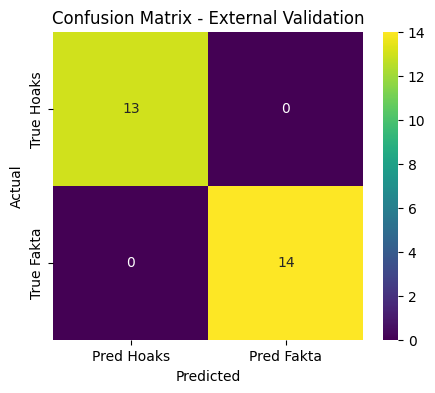

In [39]:
# ===============================
# NEW FEATURE -- External Validation
# Evaluasi Metrik (HANYA berita berstatus Correct/Wrong, tidak termasuk Rejected)
# ===============================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

processed_df = results_df[results_df["Status"] != "Rejected"].copy()

print("=" * 60)
print("EVALUASI EXTERNAL VALIDATION (berita yang berhasil diproses)")
print("=" * 60)

if len(processed_df) == 0:
    print("[PERINGATAN] Tidak ada berita yang berhasil diproses (semua Rejected), metrik tidak dapat dihitung.")
else:
    y_true_ext = processed_df["Ground Truth"]
    y_pred_ext = processed_df["Prediction"]
    label_order = ["Hoaks", "Fakta"]

    acc = accuracy_score(y_true_ext, y_pred_ext)
    prec = precision_score(y_true_ext, y_pred_ext, labels=label_order, average="weighted", zero_division=0)
    rec = recall_score(y_true_ext, y_pred_ext, labels=label_order, average="weighted", zero_division=0)
    f1 = f1_score(y_true_ext, y_pred_ext, labels=label_order, average="weighted", zero_division=0)

    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_true_ext, y_pred_ext, labels=label_order, zero_division=0))

    cm = confusion_matrix(y_true_ext, y_pred_ext, labels=label_order)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="viridis",
                xticklabels=[f"Pred {l}" for l in label_order],
                yticklabels=[f"True {l}" for l in label_order])
    plt.title("Confusion Matrix - External Validation")
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.show()


STATISTIK EXTERNAL VALIDATION
Total Berita     : 30
Total Correct    : 27
Total Wrong      : 0
Total Rejected   : 3
Acceptance Rate  : 90.00%
Rejection Rate   : 10.00%
Correct Rate     : 90.00%
Wrong Rate       : 0.00%


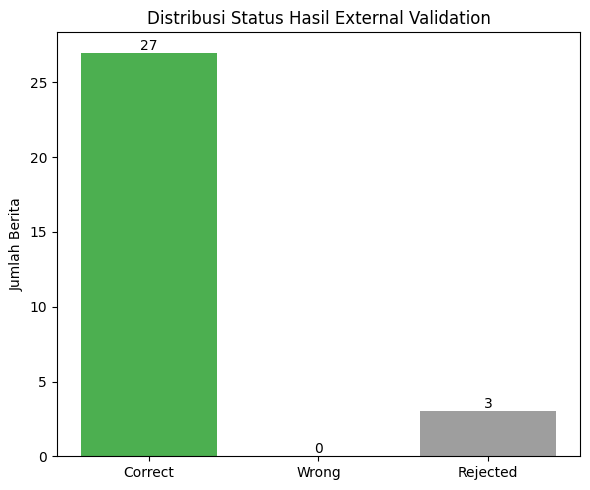

In [40]:
# ===============================
# NEW FEATURE -- External Validation
# Statistik Tambahan
# ===============================

total_n = len(results_df)
correct_n = int((results_df["Status"] == "Correct").sum())
wrong_n = int((results_df["Status"] == "Wrong").sum())
rejected_n = int((results_df["Status"] == "Rejected").sum())

acceptance_rate = (correct_n + wrong_n) / total_n * 100 if total_n else 0
rejection_rate = rejected_n / total_n * 100 if total_n else 0
correct_rate = correct_n / total_n * 100 if total_n else 0
wrong_rate = wrong_n / total_n * 100 if total_n else 0

print("=" * 40)
print("STATISTIK EXTERNAL VALIDATION")
print("=" * 40)
print(f"Total Berita     : {total_n}")
print(f"Total Correct    : {correct_n}")
print(f"Total Wrong      : {wrong_n}")
print(f"Total Rejected   : {rejected_n}")
print(f"Acceptance Rate  : {acceptance_rate:.2f}%")
print(f"Rejection Rate   : {rejection_rate:.2f}%")
print(f"Correct Rate     : {correct_rate:.2f}%")
print(f"Wrong Rate       : {wrong_rate:.2f}%")

plt.figure(figsize=(6, 5))
bars = plt.bar(["Correct", "Wrong", "Rejected"], [correct_n, wrong_n, rejected_n],
                color=["#4CAF50", "#F44336", "#9E9E9E"])
plt.title("Distribusi Status Hasil External Validation")
plt.ylabel("Jumlah Berita")
plt.bar_label(bars)
plt.tight_layout()
plt.show()


In [42]:
# ===============================
# NEW FEATURE -- External Validation
# Export Hasil & Preview
# ===============================

EXPORT_COLUMNS = ["No", "Source", "URL", "Title", "Category", "Ground Truth", "Prediction", "Status", "Confidence", "GPT Summary"]

results_df[EXPORT_COLUMNS].to_csv("external_validation_results.csv", index=False, encoding="utf-8-sig")
print("[OK] Hasil disimpan ke external_validation_results.csv")

print("\n10 Baris Pertama Hasil Prediksi:")
display(results_df[EXPORT_COLUMNS].head(10))

print("\nRingkasan Statistik:")
print(f"Total Berita   : {total_n}")
print(f"Correct        : {correct_n} ({correct_rate:.2f}%)")
print(f"Wrong          : {wrong_n} ({wrong_rate:.2f}%)")
print(f"Rejected       : {rejected_n} ({rejection_rate:.2f}%)")
if len(processed_df):
    print(f"Accuracy (berita diproses) : {accuracy_score(processed_df['Ground Truth'], processed_df['Prediction']):.4f}")


[OK] Hasil disimpan ke external_validation_results.csv

10 Baris Pertama Hasil Prediksi:


,No,Source,URL,Title,Category,Ground Truth,Prediction,Status,Confidence,GPT Summary
0,1,TurnBackHoax.id,https://turnbackhoax.id/articles/35493-salah-p...,[SALAH] Prabowo Panggil Jokowi ke Istana untuk...,Politik & Pemerintahan,Hoaks,Hoaks,Correct,89.58,Berita yang beredar tentang Prabowo memanggil ...
1,2,TurnBackHoax.id,[SALAH] DPR Resmi Tolak Pengesahan RUU Perampa...,[SALAH] DPR Resmi Tolak Pengesahan RUU Perampa...,Politik & Pemerintahan,Hoaks,Hoaks,Correct,92.86,Berita ini adalah fakta yang mengklarifikasi b...
2,3,Komdigi.go.id,Kementerian Komunikasi dan Digital,[HOAKS] Puan Maharani Minta Pemerintah Genjot ...,Politik & Pemerintahan,Hoaks,Hoaks,Correct,72.22,Berita tersebut adalah fakta. Video yang bered...
3,4,Kompas.com,https://www.kompas.com/cekfakta/read/2026/07/2...,[HOAKS] Gedung DPR Dibakar Demonstran pada 22 ...,Politik & Pemerintahan,Hoaks,Hoaks,Correct,72.41,Berita yang menyebutkan bahwa Gedung DPR dibak...
4,5,TurnBackHoax.id,[SALAH] Prabowo Bakal Ubah IKN Jadi Markas Bes...,[SALAH] Prabowo Bakal Ubah IKN Jadi Markas Bes...,Politik & Pemerintahan,Hoaks,Hoaks,Correct,100.00,Berita tersebut merupakan fakta yang mengklari...
5,6,Kompas.com,[HOAKS] Tautan Pendaftaran Bantuan BLT UMKM 20...,[HOAKS] Tautan Pendaftaran Bantuan BLT UMKM 20...,Ekonomi,Hoaks,-,Rejected,52.38,
6,7,Kompas.com,[HOAKS] Utang Indonesia Tembus Rp 10.000 Trili...,[HOAKS] Utang Indonesia Tembus Rp 10.000 Trili...,Ekonomi,Hoaks,Hoaks,Correct,93.06,Berita yang beredar tentang utang Indonesia te...
7,8,TurnBackHoax.id,https://turnbackhoax.id/articles/35861-salah-b...,[SALAH] Bank Indonesia Menerbitkan Uang Kertas...,Ekonomi,Hoaks,Hoaks,Correct,100.00,Berita yang menyebut Bank Indonesia menerbitka...
8,9,Komdigi.gp.id,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Kopdes Merah Putih Tawarkan Pinjaman h...,Ekonomi,Hoaks,Hoaks,Correct,100.00,Berita yang mengklaim bahwa Koperasi Desa (Kop...
9,10,Kompas.com,[HOAKS] Tautan Pendaftaran Bantuan Dana Pensiu...,[HOAKS] Tautan Pendaftaran Bantuan Dana Pensiu...,Ekonomi,Hoaks,Hoaks,Correct,64.86,Berita ini terindikasi sebagai hoaks karena in...



Ringkasan Statistik:
Total Berita   : 30
Correct        : 27 (90.00%)
Wrong          : 0 (0.00%)
Rejected       : 3 (10.00%)
Accuracy (berita diproses) : 1.0000
